# Severe toxicity after day 28 of neoadjuvant chemotherapy — CALGB 40603 landmark analysis

**Primary outcome (`heme`).** First grade ≥3 neutropenia, leukopenia, thrombocytopenia or febrile neutropenia (CTCAE v3.0) with onset after day 28, among patients free of such an event on or before day 28.

**Comparison outcome (`any`).** First grade ≥3 adverse event (AE) of any type after day 28, among patients free of any grade ≥3 AE on or before day 28.

**RQ6.** Specific outcomes (the hematologic composite, its components and the most frequent non-hematologic grade ≥3 AEs) versus any grade ≥3 AE, each with baseline variables alone and with baseline variables plus early AEs.

**Predictors.** 19 baseline variables and 18 AE summaries restricted to AEs with onset ≤ day 28.

**Evaluation.** Nested cross-validation (5 outer × 4 inner stratified folds, seeds 1, 42, 2024). Imputation, scaling, encoding, resampling, feature reduction, hyperparameters, model family, decision threshold and risk-tier cut-points are all fitted on training folds only. Every experiment in Sections 5–19 is run for both `heme` and `any`.

## 0. Setup

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, f1_score,
                             fbeta_score, brier_score_loss)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline          # allows resampling steps inside the CV pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

TARGETS  = {"heme": "Hematologic grade >=3", "any": "Any grade >=3 AE"}
DATA     = "data"
LANDMARK = 28                         # days from registration
SEEDS    = [1, 42, 2024]
N_OUTER, N_INNER = 5, 4
ROB_SEEDS = [7, 99, 314, 777, 2025]   # unseen seeds for the robustness check
T0 = time.time()

## 1. Data

`treated2.csv` (one row per patient) and `aeclean.csv` (one row per AE) are used as distributed by Project Data Sphere. Code 9 (unknown) in grade and clinical T/N is treated as missing. AEs without a grade or onset day are dropped.

In [2]:
patients = pd.read_csv(f"{DATA}/treated2.csv")
ae = pd.read_csv(f"{DATA}/aeclean.csv")
for c in ["GRADE", "clinicalt", "clinicaln"]:
    patients[c] = patients[c].replace(9, np.nan)
ae = ae[ae.GRADE_ID.between(1, 5) & ae.aestart.notna()].copy()

HEME = {"Neutropenia": "Neutrophils/granulocytes (ANC/AGC)",
        "Leukopenia": "Leukocytes (total WBC)",
        "Thrombocytopenia": "Platelets"}
ae["htype"] = ae.EVENTNAME.map({v: k for k, v in HEME.items()})
ae.loc[ae.EVENTNAME.str.startswith("Febrile neutropenia"), "htype"] = "Febrile neutropenia"
TYPES = ["Neutropenia", "Leukopenia", "Febrile neutropenia", "Thrombocytopenia"]

# toxicity groups used only for early-AE features (first matching rule wins)
GROUP_RULES = [
    ("Neutropenia",      ae.EVENTNAME.isin(["Neutrophils/granulocytes (ANC/AGC)", "Leukocytes (total WBC)"])),
    ("Febrile neutropenia", ae.EVENTNAME.str.startswith("Febrile neutropenia")),
    ("Thrombocytopenia", ae.EVENTNAME.eq("Platelets")),
    ("Anemia",           ae.EVENTNAME.eq("Hemoglobin")),
    ("Infection",        ae.CATEGORY.eq("INFECTION")),
    ("Fatigue",          ae.EVENTNAME.str.startswith("Fatigue")),
    ("Hypertension",     ae.EVENTNAME.eq("Hypertension")),
    ("Neuropathy",       ae.EVENTNAME.str.startswith("Neuropathy:")),
    ("GI",               ae.CATEGORY.eq("GASTROINTESTINAL")),
    ("Pain",             ae.CATEGORY.eq("PAIN")),
    ("Metabolic_lab",    ae.CATEGORY.eq("METABOLIC/LABORATORY")),
    ("Thrombosis",       ae.EVENTNAME.str.startswith("Thrombosis")),
]
ae["group"] = None
for name, mask in GROUP_RULES:
    ae.loc[mask & ae.group.isna(), "group"] = name
GROUPS = ["Neutropenia", "Thrombocytopenia", "Fatigue", "GI", "Neuropathy", "Pain", "Infection", "Hypertension", "Metabolic_lab"]
print(len(patients), "patients |", len(ae), "adverse events")

443 patients | 15372 adverse events


## 2. Features

Baseline variables are known before treatment (the randomized arm included). Early-AE features use only AEs with onset ≤ day 28. Dose modifications and doses received are not used: they are determined after the landmark.

In [3]:
BASE = ["AGE_C", "WHITE", "GRADE", "clinicalt", "clinicaln", "er", "pgr", "histotype", "meno", "her2fish", "her2ihc",
        "tsizepe", "tsizemamm", "tsizeultra", "tsizemri", "indrx", "factora", "factorb", "stra1_stage"]
CATEGORICAL = ["indrx", "WHITE", "histotype", "GRADE", "clinicalt", "clinicaln", "meno", "er", "pgr", "her2ihc", "AGE_C", "stra1_stage"]

def early_features(L):
    e = ae[ae.aestart <= L]
    f = e.groupby("MASK_ID").agg(e_count=("EVENTNAME", "count"),
                                 e_max_grade=("GRADE_ID", "max"),
                                 e_n_types=("EVENTNAME", "nunique"),
                                 e_first_day=("aestart", "min"))
    f["e_count_g2"] = e[e.GRADE_ID >= 2].groupby("MASK_ID").size()
    for g in GROUPS:
        f["e_max_" + g.lower()] = e[e.group == g].groupby("MASK_ID").GRADE_ID.max()
    for t in TYPES:
        f["e_max_" + t.split(" ")[0].lower() + "_h"] = e[e.htype == t].groupby("MASK_ID").GRADE_ID.max()
    X = patients[["MASK_ID"] + BASE].merge(f.reset_index(), on="MASK_ID", how="left")
    early = [c for c in X.columns if c.startswith("e_")]
    zero = [c for c in early if c != "e_first_day"]
    X[zero] = X[zero].fillna(0)                        # no AE by day L -> count/grade 0
    X["e_first_day"] = X["e_first_day"].fillna(L + 1)  # no AE by day L -> "after the window"
    return X, early

X_all, EARLY = early_features(LANDMARK)
FEATURES = BASE + EARLY
print(len(BASE), "baseline +", len(EARLY), "early-AE features =", len(FEATURES))

19 baseline + 18 early-AE features = 37


## 3. Landmark cohorts

For each outcome, patients whose first qualifying grade ≥3 event occurred on or before day 28 are excluded (outcome already known). Among the rest, y = 1 if the first event occurred after day 28, otherwise 0. `OUTCOMES` also holds the specific outcomes used in Section 20 (RQ6).

In [4]:
OUTCOMES = {
    "heme":                ae.htype.notna(),                                   # hematologic composite (primary)
    "any":                 pd.Series(True, index=ae.index),                     # any grade >=3 AE
    "Neutropenia":         ae.htype.eq("Neutropenia"),
    "Leukopenia":          ae.htype.eq("Leukopenia"),
    "Thrombocytopenia":    ae.htype.eq("Thrombocytopenia"),
    "Febrile neutropenia": ae.htype.eq("Febrile neutropenia"),
    "Infection":           ae.CATEGORY.eq("INFECTION"),
    "Fatigue":             ae.EVENTNAME.str.startswith("Fatigue"),
    "Gastrointestinal":    ae.CATEGORY.eq("GASTROINTESTINAL"),
}

def cohort(outcome):
    ev = ae[OUTCOMES[outcome] & (ae.GRADE_ID >= 3)]
    first = ev.groupby("MASK_ID").aestart.min()
    t = X_all.MASK_ID.map(first)
    d = X_all[~(t <= LANDMARK)].copy().reset_index(drop=True)
    d["y"] = d.MASK_ID.map(first).gt(LANDMARK).astype(int)
    d["carbo"] = d.indrx.isin([3, 4]).astype(int)   # arms 3-4 include carboplatin
    return d

D = {}
for T in TARGETS:
    d = cohort(T)
    D[T] = dict(d=d, X=d[FEATURES], y=d.y.values)
    y = D[T]["y"]
    print(f"== {T}: {TARGETS[T]}")
    print("Patients at risk:", len(d))
    print("Events (y=1):", y.sum(), f"({y.mean():.1%})", "| no event (y=0):", (y == 0).sum())
    print("Excluded (event on or before day 28):", len(X_all) - len(d))
    print(pd.crosstab(d.carbo.map({0: "no carboplatin", 1: "carboplatin"}), d.y, margins=True), "\n")

== heme: Hematologic grade >=3
Patients at risk: 366
Events (y=1): 134 (36.6%) | no event (y=0): 232
Excluded (event on or before day 28): 77
y                 0    1  All
carbo                        
carboplatin      70   90  160
no carboplatin  162   44  206
All             232  134  366 

== any: Any grade >=3 AE
Patients at risk: 310
Events (y=1): 178 (57.4%) | no event (y=0): 132
Excluded (event on or before day 28): 133
y                 0    1  All
carbo                        
carboplatin      37  102  139
no carboplatin   95   76  171
All             132  178  310 



Descriptive only (not used for feature selection):

In [5]:
pd.concat({T: pd.DataFrame({"missing": D[T]["X"].isna().mean().round(2),
                            "mean (y=0)": D[T]["X"][D[T]["y"] == 0].mean().round(2),
                            "mean (y=1)": D[T]["X"][D[T]["y"] == 1].mean().round(2)}) for T in TARGETS}, axis=1)

heme                           any                      
                         missing mean (y=0) mean (y=1) missing mean (y=0) mean (y=1)
AGE_C                       0.00       1.90       1.99    0.00       1.84       1.98
WHITE                       0.00       1.26       1.30    0.00       1.18       1.34
GRADE                       0.11       2.85       2.83    0.11       2.89       2.83
clinicalt                   0.01       2.08       2.15    0.01       2.16       2.08
clinicaln                   0.05       0.68       0.69    0.06       0.71       0.68
er                          0.01       1.08       1.04    0.02       1.07       1.06
pgr                         0.02       1.03       1.05    0.02       1.02       1.04
histotype                   0.01       1.25       1.25    0.02       1.26       1.23
meno                        0.01       0.45       0.46    0.01       0.43       0.44
her2fish                    0.67       1.23       1.25    0.67       1.25       1.25
her2ihc                     0.15       1.61       1.60    0.14       1.61       1.62
tsizepe                     0.09       4.57       4.52    0.08       4.80       4.34
tsizemamm                   0.38       3.12       3.18    0.38       3.06       3.06
tsizeultra                  0.24       2.80       2.96    0.25       2.65       2.90
tsizemri                    0.31       3.92       3.98    0.31       4.10       3.75
indrx                       0.00       2.08       2.92    0.00       1.98       2.67
factora                     0.00       0.30       0.67    0.00       0.28       0.57
factorb                     0.00       0.47       0.57    0.00       0.42       0.52
stra1_stage                 0.00       1.32       1.34    0.00       1.33       1.30
e_count                     0.00       7.87       8.84    0.00       7.35       7.74
e_max_grade                 0.00       1.71       1.94    0.00       1.47       1.64
e_n_types                   0.00       7.33       8.46    0.00       6.85       7.34
e_first_day                 0.00       7.22       6.97    0.00       7.36       7.23
e_count_g2                  0.00       1.48       2.40    0.00       1.21       1.69
e_max_neutropenia           0.00       0.32       0.78    0.00       0.31       0.61
e_max_thrombocytopenia      0.00       0.08       0.33    0.00       0.07       0.22
e_max_fatigue               0.00       0.76       0.87    0.00       0.74       0.80
e_max_gi                    0.00       0.73       1.02    0.00       0.67       0.88
e_max_neuropathy            0.00       0.46       0.50    0.00       0.39       0.46
e_max_pain                  0.00       0.67       0.65    0.00       0.59       0.58
e_max_infection             0.00       0.20       0.24    0.00       0.16       0.17
e_max_hypertension          0.00       0.34       0.38    0.00       0.24       0.22
e_max_metabolic_lab         0.00       0.47       0.51    0.00       0.39       0.33
e_max_neutropenia_h         0.00       0.24       0.68    0.00       0.21       0.52
e_max_leukopenia_h          0.00       0.17       0.27    0.00       0.16       0.21
e_max_febrile_h             0.00       0.00       0.00    0.00       0.00       0.00
e_max_thrombocytopenia_h    0.00       0.08       0.33    0.00       0.07       0.22

## 4. Evaluation utilities

### 4.1 Metrics

In [6]:
def metrics(y_true, prob, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y_true, prob),
                PR_AUC=average_precision_score(y_true, prob),
                Accuracy=(tp + tn) / len(y_true),
                Sensitivity=tp / max(tp + fn, 1),
                Specificity=tn / max(tn + fp, 1),
                Precision=tp / max(tp + fp, 1),
                NPV=tn / max(tn + fn, 1),
                F1=f1_score(y_true, pred, zero_division=0),
                F2=fbeta_score(y_true, pred, beta=2, zero_division=0),
                Brier=brier_score_loss(y_true, np.clip(prob, 0, 1)),
                TN=tn, FP=fp, FN=fn, TP=tp)

### 4.2 Threshold selection

Default rule: Youden's J, which balances sensitivity and specificity (F2 would select "flag everyone" for the `any` outcome, whose prevalence is 57%). The threshold is always chosen on inner out-of-fold probabilities of the training portion; other rules are compared in Section 14.

In [7]:
def choose_threshold(y_tr, p_tr, rule="youden"):
    grid = np.unique(np.round(p_tr, 4))
    best_t, best_s = 0.5, -np.inf
    for t in grid:
        pr = (p_tr >= t).astype(int)
        tp = ((pr == 1) & (y_tr == 1)).sum(); tn = ((pr == 0) & (y_tr == 0)).sum()
        sens, spec = tp / y_tr.sum(), tn / (y_tr == 0).sum()
        if rule == "youden": s = sens + spec - 1
        elif rule == "f2":   s = fbeta_score(y_tr, pr, beta=2, zero_division=0)
        elif rule == "f1":   s = f1_score(y_tr, pr, zero_division=0)
        elif rule == "sens80": s = spec if sens >= 0.80 else -1   # max specificity subject to sensitivity >= 0.80
        elif rule == "acc":  s = (tp + tn) / len(y_tr)
        if s > best_s: best_s, best_t = s, t
    return best_t

### 4.3 Pipeline

All learned steps (missingness filter, imputation, scaling, encoding, resampling, reduction, classifier) are pipeline steps, so they are refitted on each training fold.

In [8]:
class DropSparse(BaseEstimator, TransformerMixin):
    # drops columns whose missing fraction in the training fold exceeds max_missing
    def __init__(self, max_missing=1.0): self.max_missing = max_missing
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.keep_ = np.isnan(X).mean(axis=0) <= self.max_missing
        if not self.keep_.any(): self.keep_[:] = True
        return self
    def transform(self, X): return np.asarray(X, dtype=float)[:, self.keep_]

SCALERS = {"standard": StandardScaler(), "robust": RobustScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}
def IMPUTERS(kind, ind):
    if kind == "median": return SimpleImputer(strategy="median", add_indicator=ind)
    if kind == "mean":   return SimpleImputer(strategy="mean", add_indicator=ind)
    if kind == "knn":    return KNNImputer(n_neighbors=10, add_indicator=ind)
    if kind == "iterative": return IterativeImputer(max_iter=10, random_state=0, add_indicator=ind)

def make_prep(impute="median", scale="standard", cat="onehot", indicator=False, max_missing=1.0, features=FEATURES):
    num = [c for c in features if c not in CATEGORICAL]
    cats = [c for c in features if c in CATEGORICAL]
    num_pipe = Pipeline([("drop", DropSparse(max_missing)), ("imp", IMPUTERS(impute, indicator)), ("sc", clone(SCALERS[scale]) if scale != "none" else "passthrough")])
    if cat == "onehot":
        cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    else:  # ordinal: codes kept as numbers
        cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())])
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cats)])

def make_pipe(model, prep=None, sampler="passthrough", reduce="passthrough"):
    return Pipeline([("prep", prep if prep is not None else make_prep()), ("sampler", sampler), ("reduce", reduce), ("model", model)])

### 4.4 Nested cross-validation

Outer loop: 5 stratified folds for evaluation. Inner loop (training portion only): 4-fold grid search by AUC, then threshold and tertile cut-points from inner out-of-fold probabilities. The refitted model scores the outer test fold once. Metrics are computed on pooled outer predictions per seed and averaged over seeds.

In [9]:
def nested_cv(pipe, grid, Xd, y, seeds=SEEDS, rule="youden", return_detail=False):
    rows, detail = [], []
    for s in seeds:
        outer = StratifiedKFold(N_OUTER, shuffle=True, random_state=s)
        prob, pred, train_auc, tert = np.zeros(len(y)), np.zeros(len(y), int), [], np.zeros(len(y), int)
        for tr, te in outer.split(Xd, y):
            inner = StratifiedKFold(N_INNER, shuffle=True, random_state=s)
            gs = GridSearchCV(clone(pipe), grid, cv=inner, scoring="roc_auc", n_jobs=2) if grid else None
            best = gs.fit(Xd.iloc[tr], y[tr]).best_estimator_ if grid else clone(pipe)
            p_in = cross_val_predict(clone(best), Xd.iloc[tr], y[tr], cv=inner, method="predict_proba")[:, 1]
            thr = choose_threshold(y[tr], p_in, rule)
            cuts = np.quantile(p_in, [1/3, 2/3])
            best.fit(Xd.iloc[tr], y[tr])
            prob[te] = best.predict_proba(Xd.iloc[te])[:, 1]
            pred[te] = (prob[te] >= thr).astype(int)
            tert[te] = np.digitize(prob[te], cuts)            # 0 low, 1 intermediate, 2 high
            train_auc.append(roc_auc_score(y[tr], best.predict_proba(Xd.iloc[tr])[:, 1]))
        m = metrics(y, prob, pred); m["Train_AUC"] = np.mean(train_auc); m["seed"] = s
        rows.append(m); detail.append(dict(prob=prob, pred=pred, tert=tert))
    R = pd.DataFrame(rows)
    summary = R.drop(columns="seed").mean()
    summary["AUC_sd"] = R.AUC.std()
    return (summary, detail) if return_detail else summary

def run_table(configs, X, y, **kw):
    out = {}
    for name, (pipe, grid) in configs.items():
        t = time.time(); out[name] = nested_cv(pipe, grid, X, y, **kw)
        print(f"{name:40s} AUC={out[name]['AUC']:.3f}  ({time.time()-t:.0f}s)")
    cols = ["AUC", "AUC_sd", "Train_AUC", "PR_AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Brier"]
    return pd.DataFrame(out).T[cols].astype(float).round(3)

def per_target(fn):
    # runs fn(T) for every target and stacks the returned tables with the target as the outer index
    out = {}
    for T in TARGETS:
        print(f"--- {T}"); out[T] = fn(T)
    return out
stack = lambda res: pd.concat(res, names=["target", ""])

## 5. Baselines

Arm-only logistic regression (nested) and a fixed rule that needs no fitting. Rules: `heme` — ANC or platelet grade ≥1 by day 28; `any` — any AE grade ≥2 by day 28.

In [10]:
RULES = {"heme": ("Rule: ANC or platelet grade >=1 by day 28", lambda d: (d.e_max_neutropenia_h >= 1) | (d.e_max_thrombocytopenia_h >= 1)),
         "any":  ("Rule: any AE grade >=2 by day 28",          lambda d: d.e_max_grade >= 2)}
def baselines_for(T):
    d, y = D[T]["d"], D[T]["y"]
    arm = nested_cv(make_pipe(LogisticRegression(max_iter=5000), prep=make_prep(features=["indrx"])), None, d[["indrx"]], y)
    name, f = RULES[T]; r = f(d).astype(int).values
    D[T]["arm_only"], D[T]["rule_name"], D[T]["rule_m"] = arm, name, pd.Series(metrics(y, r, r))
    return pd.DataFrame({"Arm only (LR)": arm, name: D[T]["rule_m"]}).T[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2"]].astype(float).round(3)
stack(per_target(baselines_for))

--- heme


--- any


AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2
target                                                                                                                     
heme   Arm only (LR)                              0.683     0.689        0.672        0.698      0.562  0.786  0.612  0.647
       Rule: ANC or platelet grade >=1 by day 28  0.656     0.694        0.515        0.797      0.595  0.740  0.552  0.529
any    Arm only (LR)                              0.624     0.635        0.573        0.720      0.734  0.556  0.644  0.599
       Rule: any AE grade >=2 by day 28           0.569     0.590        0.713        0.424      0.626  0.523  0.667  0.694

## 6. Preprocessing

L2 logistic regression with C tuned in the inner loop; only the preprocessing changes.

In [11]:
LRb = LogisticRegression(max_iter=5000, class_weight="balanced")
gC = {"model__C": [0.01, 0.1, 1]}
prep_cfg = {
    "median + standard + onehot (default)": make_prep(),
    "mean + standard + onehot":            make_prep(impute="mean"),
    "knn + standard + onehot":             make_prep(impute="knn"),
    "iterative + standard + onehot":       make_prep(impute="iterative"),
    "median + missing indicator":          make_prep(indicator=True),
    "median + robust scaler":              make_prep(scale="robust"),
    "median + minmax scaler":              make_prep(scale="minmax"),
    "median + ordinal categories":         make_prep(cat="ordinal"),
    "median + drop >50% missing":          make_prep(max_missing=0.5),
}
res_prep = per_target(lambda T: run_table({k: (make_pipe(LRb, prep=v), gC) for k, v in prep_cfg.items()}, D[T]["X"], D[T]["y"]))
stack(res_prep)

--- heme


median + standard + onehot (default)     AUC=0.734  (7s)


mean + standard + onehot                 AUC=0.733  (5s)


knn + standard + onehot                  AUC=0.735  (7s)


iterative + standard + onehot            AUC=0.731  (71s)


median + missing indicator               AUC=0.726  (6s)


... (10 outputs left out)

median + minmax scaler                   AUC=0.690  (5s)


median + ordinal categories              AUC=0.689  (4s)


median + drop >50% missing               AUC=0.675  (6s)


AUC  AUC_sd  Train_AUC  PR_AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2  Brier
target                                                                                                                                                  
heme   median + standard + onehot (default)  0.734   0.006      0.788   0.609     0.662        0.590        0.704      0.536  0.749  0.560  0.577  0.209
       mean + standard + onehot              0.733   0.006      0.787   0.609     0.670        0.582        0.721      0.548  0.750  0.562  0.574  0.210
       knn + standard + onehot               0.735   0.005      0.789   0.609     0.663        0.619        0.688      0.536  0.759  0.573  0.599  0.209
       iterative + standard + onehot         0.731   0.005      0.790   0.603     0.663        0.580        0.711      0.541  0.748  0.554  0.568  0.210
       median + missing indicator            0.726   0.002      0.790   0.610     0.661        0.617        0.687      0.536  0.759  0.569  0.596  0.210
       median + robust scaler                0.710   0.013      0.796   0.575     0.660        0.590        0.701      0.536  0.748  0.558  0.576  0.218
       median + minmax scaler                0.724   0.002      0.778   0.594     0.680        0.684        0.678      0.551  0.788  0.610  0.653  0.227
       median + ordinal categories           0.737   0.007      0.798   0.599     0.661        0.659        0.662      0.532  0.773  0.586  0.627  0.209
       median + drop >50% missing            0.735   0.005      0.787   0.609     0.662        0.600        0.698      0.537  0.753  0.564  0.584  0.209
any    median + standard + onehot (default)  0.676   0.013      0.768   0.735     0.632        0.614        0.657      0.708  0.558  0.657  0.631  0.228
       mean + standard + onehot              0.676   0.014      0.773   0.729     0.629        0.609        0.657      0.706  0.554  0.653  0.626  0.228
       knn + standard + onehot               0.675   0.012      0.765   0.732     0.623        0.569        0.694      0.715  0.545  0.634  0.593  0.228
       iterative + standard + onehot         0.670   0.010      0.762   0.726     0.622        0.609        0.639      0.695  0.548  0.649  0.624  0.230
       median + missing indicator            0.669   0.007      0.780   0.727     0.609        0.599        0.621      0.681  0.534  0.638  0.614  0.229
       median + robust scaler                0.673   0.006      0.778   0.729     0.626        0.596        0.667      0.707  0.550  0.646  0.615  0.231
       median + minmax scaler                0.690   0.007      0.759   0.731     0.649        0.581        0.742      0.753  0.568  0.655  0.608  0.233
       median + ordinal categories           0.689   0.007      0.772   0.751     0.631        0.577        0.705      0.727  0.553  0.642  0.601  0.224
       median + drop >50% missing            0.675   0.018      0.774   0.724     0.635        0.627        0.646      0.706  0.564  0.663  0.641  0.230

## 7. Simple learners

In [12]:
simple_cfg = {
    "LR L2 (Ridge)":     (make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")), {"model__C": [0.001, 0.01, 0.1, 1, 10]}),
    "LR L1 (Lasso)":     (make_pipe(LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced")), {"model__C": [0.01, 0.05, 0.1, 0.5, 1]}),
    "LR ElasticNet":     (make_pipe(LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000, class_weight="balanced")), {"model__C": [0.01, 0.1, 1], "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "LDA (shrinkage)":   (make_pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"model__shrinkage": ["auto", 0.1, 0.5, 0.9]}),
    "Decision Tree":     (make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=0)), {"model__max_depth": [2, 3, 4, 5], "model__min_samples_leaf": [10, 20, 40]}),
    "KNN":               (make_pipe(KNeighborsClassifier()), {"model__n_neighbors": [15, 31, 51], "model__weights": ["uniform", "distance"]}),
    "SVM (RBF)":         (make_pipe(SVC(probability=True, class_weight="balanced", random_state=0)), {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01]}),
    "Naive Bayes":       (make_pipe(GaussianNB()), {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}),
}
res_simple = per_target(lambda T: run_table(simple_cfg, D[T]["X"], D[T]["y"]))
stack(res_simple)

--- heme


LR L2 (Ridge)                            AUC=0.721  (7s)


LR L1 (Lasso)                            AUC=0.733  (7s)


LR ElasticNet                            AUC=0.730  (16s)


LDA (shrinkage)                          AUC=0.720  (6s)


Decision Tree                            AUC=0.694  (12s)


... (8 outputs left out)

KNN                                      AUC=0.650  (7s)


SVM (RBF)                                AUC=0.640  (11s)


Naive Bayes                              AUC=0.593  (5s)


AUC  AUC_sd  Train_AUC  PR_AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2  Brier
target                                                                                                                             
heme   LR L2 (Ridge)    0.721   0.017      0.779   0.603     0.659        0.565        0.714      0.534  0.740  0.547  0.557  0.216
       LR L1 (Lasso)    0.733   0.004      0.763   0.605     0.671        0.669        0.672      0.543  0.782  0.596  0.637  0.213
       LR ElasticNet    0.730   0.009      0.762   0.599     0.668        0.682        0.659      0.536  0.783  0.600  0.646  0.216
       LDA (shrinkage)  0.720   0.005      0.780   0.612     0.669        0.552        0.737      0.552  0.742  0.548  0.549  0.241
       Decision Tree    0.694   0.017      0.783   0.569     0.637        0.642        0.634      0.507  0.756  0.563  0.607  0.228
       KNN              0.723   0.002      0.796   0.593     0.687        0.555        0.763      0.579  0.748  0.564  0.558  0.202
       SVM (RBF)        0.713   0.010      0.807   0.595     0.668        0.592        0.711      0.542  0.751  0.566  0.581  0.201
       Naive Bayes      0.673   0.018      0.771   0.528     0.668        0.478        0.779      0.558  0.721  0.513  0.491  0.319
any    LR L2 (Ridge)    0.657   0.020      0.755   0.710     0.625        0.562        0.710      0.723  0.546  0.632  0.588  0.236
       LR L1 (Lasso)    0.671   0.008      0.769   0.721     0.627        0.582        0.687      0.716  0.550  0.642  0.605  0.232
       LR ElasticNet    0.679   0.014      0.776   0.726     0.616        0.582        0.662      0.700  0.540  0.635  0.602  0.229
       LDA (shrinkage)  0.673   0.007      0.762   0.736     0.615        0.562        0.687      0.707  0.538  0.626  0.586  0.262
       Decision Tree    0.589   0.027      0.742   0.656     0.571        0.569        0.573      0.643  0.497  0.603  0.582  0.264
       KNN              0.650   0.007      0.839   0.701     0.599        0.594        0.606      0.673  0.525  0.629  0.607  0.231
       SVM (RBF)        0.640   0.042      0.741   0.695     0.590        0.599        0.578      0.659  0.516  0.627  0.610  0.229
       Naive Bayes      0.593   0.004      0.746   0.653     0.560        0.532        0.598      0.649  0.483  0.579  0.549  0.402

## 8. Ensembles

Hard voting has no probabilities; its score is the fraction of member votes.

In [13]:
from sklearn.base import ClassifierMixin
class HardVote(ClassifierMixin, BaseEstimator):
    def __init__(self, estimators=None): self.estimators = estimators
    def fit(self, X, y):
        self.fitted_ = [clone(e).fit(X, y) for _, e in self.estimators]; self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        v = np.mean([e.predict(X) for e in self.fitted_], axis=0); return np.c_[1 - v, v]
    def predict(self, X): return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

lr_  = LogisticRegression(max_iter=5000, class_weight="balanced", C=0.1)
rf_  = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", random_state=0, n_jobs=1)
gb_  = GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)
svm_ = SVC(probability=True, class_weight="balanced", C=1, random_state=0)
ens_cfg = {
    "Random Forest":      (make_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)), {"model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.3]}),
    "Extra Trees":        (make_pipe(ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)), {"model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.3]}),
    "Gradient Boosting":  (make_pipe(GradientBoostingClassifier(n_estimators=150, subsample=0.8, random_state=0)), {"model__max_depth": [1, 2, 3], "model__learning_rate": [0.03, 0.1]}),
    "HistGradientBoosting": (make_pipe(HistGradientBoostingClassifier(max_iter=200, random_state=0)), {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1], "model__l2_regularization": [0, 1.0]}),
    "Soft Voting (LR+RF+GB)":   (make_pipe(VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft")), None),
    "Weighted Voting (2·LR+RF+GB)": (make_pipe(VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft", weights=[2, 1, 1])), None),
    "Hard Voting (LR+RF+GB)":   (make_pipe(HardVote([("lr", lr_), ("rf", rf_), ("gb", gb_)])), None),
    "Stacking (LR+RF+GB+SVM → LR)": (make_pipe(StackingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_), ("svm", svm_)],
                                       final_estimator=LogisticRegression(max_iter=5000), cv=4)), None),
}
res_ens = per_target(lambda T: run_table(ens_cfg, D[T]["X"], D[T]["y"]))
stack(res_ens)

--- heme


Random Forest                            AUC=0.738  (99s)


Extra Trees                              AUC=0.727  (88s)


Gradient Boosting                        AUC=0.723  (38s)


HistGradientBoosting                     AUC=0.708  (35s)


Soft Voting (LR+RF+GB)                   AUC=0.720  (36s)


... (8 outputs left out)

Weighted Voting (2·LR+RF+GB)             AUC=0.682  (35s)


Hard Voting (LR+RF+GB)                   AUC=0.668  (34s)


Stacking (LR+RF+GB+SVM → LR)             AUC=0.679  (165s)


AUC  AUC_sd  Train_AUC  PR_AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2  Brier
target                                                                                                                                          
heme   Random Forest                 0.738   0.011      0.822   0.617     0.646        0.664        0.635      0.512  0.767  0.578  0.627  0.209
       Extra Trees                   0.727   0.013      0.818   0.626     0.663        0.654        0.668      0.532  0.770  0.587  0.626  0.209
       Gradient Boosting             0.723   0.005      0.806   0.595     0.652        0.652        0.652      0.520  0.765  0.578  0.620  0.199
       HistGradientBoosting          0.708   0.010      0.882   0.585     0.642        0.535        0.704      0.513  0.723  0.523  0.530  0.204
       Soft Voting (LR+RF+GB)        0.720   0.003      0.892   0.589     0.646        0.622        0.659      0.513  0.751  0.562  0.597  0.205
       Weighted Voting (2·LR+RF+GB)  0.723   0.001      0.874   0.592     0.665        0.652        0.672      0.538  0.773  0.585  0.622  0.205
       Hard Voting (LR+RF+GB)        0.678   0.007      0.832   0.509     0.657        0.614        0.681      0.527  0.754  0.566  0.594  0.279
       Stacking (LR+RF+GB+SVM → LR)  0.722   0.002      0.893   0.601     0.651        0.590        0.687      0.521  0.743  0.553  0.574  0.199
any    Random Forest                 0.690   0.018      0.831   0.736     0.638        0.592        0.699      0.727  0.560  0.652  0.614  0.227
       Extra Trees                   0.689   0.022      0.848   0.733     0.633        0.575        0.712      0.731  0.554  0.643  0.600  0.225
       Gradient Boosting             0.669   0.026      0.818   0.730     0.622        0.599        0.652      0.699  0.548  0.644  0.616  0.224
       HistGradientBoosting          0.642   0.036      0.908   0.691     0.598        0.616        0.573      0.661  0.525  0.638  0.625  0.241
       Soft Voting (LR+RF+GB)        0.679   0.015      0.904   0.732     0.610        0.603        0.619      0.681  0.536  0.639  0.617  0.223
       Weighted Voting (2·LR+RF+GB)  0.682   0.013      0.881   0.735     0.618        0.569        0.684      0.713  0.540  0.631  0.592  0.223
       Hard Voting (LR+RF+GB)        0.668   0.030      0.869   0.693     0.620        0.597        0.652      0.698  0.545  0.644  0.615  0.302
       Stacking (LR+RF+GB+SVM → LR)  0.679   0.014      0.898   0.727     0.620        0.610        0.634      0.692  0.547  0.649  0.625  0.223

## 9. Regularization sweeps

Fixed values (no tuning) to show the gap between training and test AUC.

--- heme


--- any


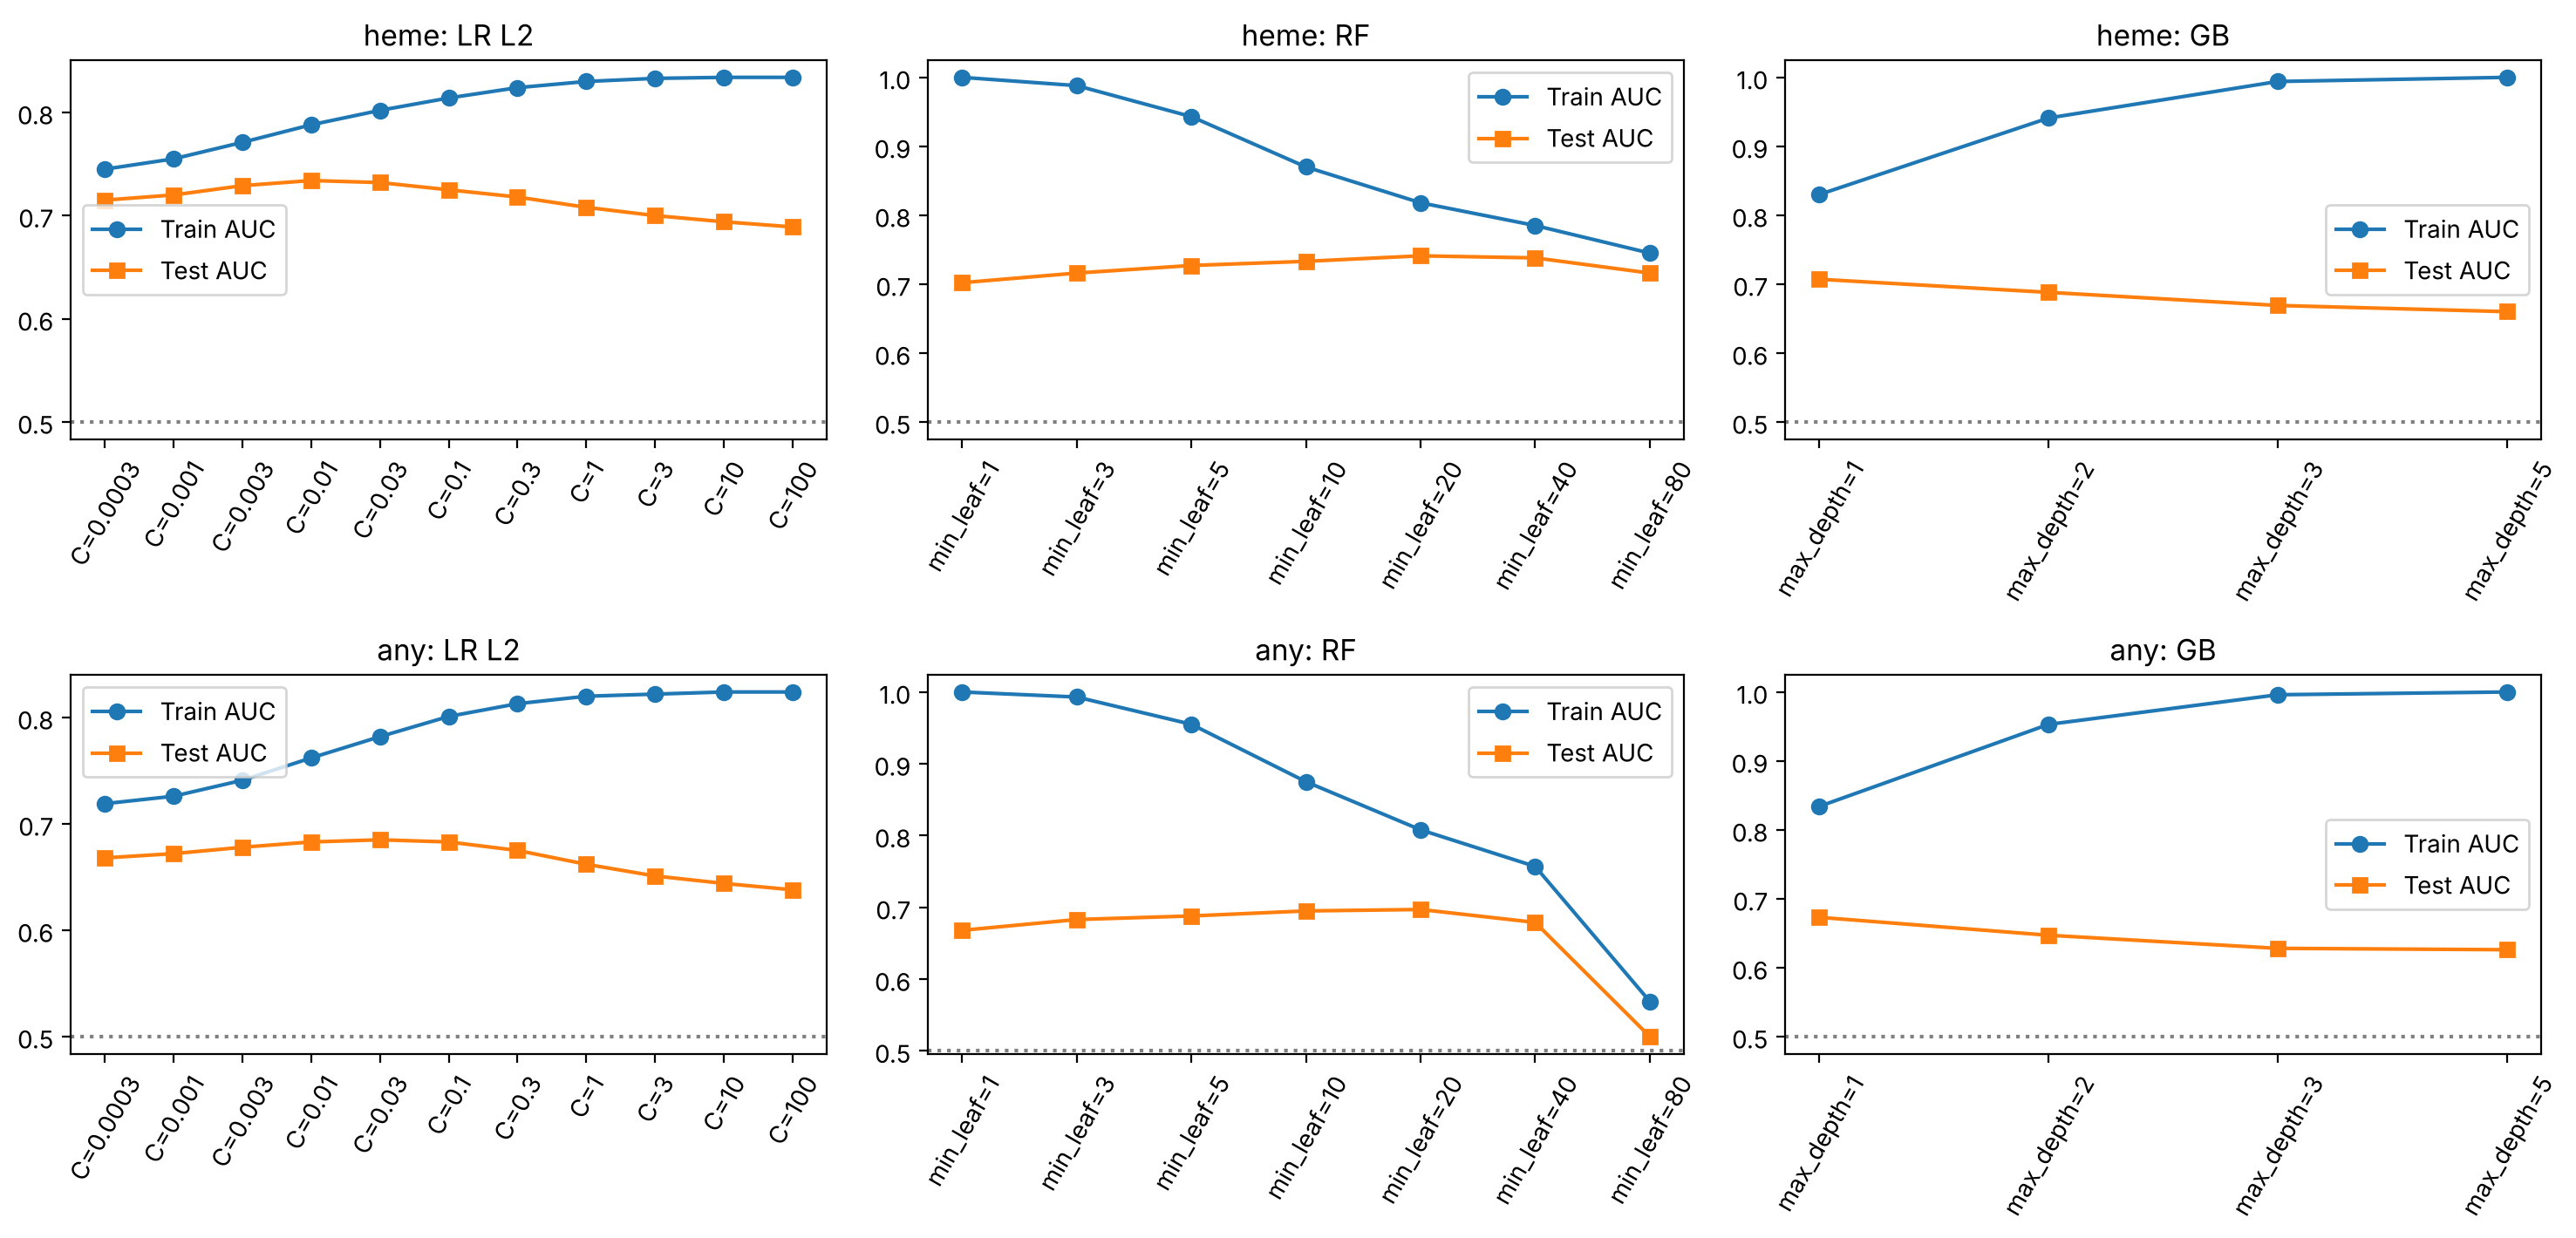

model        param  Train_AUC  Test_AUC   Sens   Spec
target                                                          
heme   0   LR L2     C=0.0003      0.745     0.715  0.542  0.795
       1   LR L2      C=0.001      0.755     0.720  0.530  0.792
       2   LR L2      C=0.003      0.771     0.729  0.542  0.764
       3   LR L2       C=0.01      0.788     0.734  0.590  0.704
       4   LR L2       C=0.03      0.802     0.732  0.627  0.680
       5   LR L2        C=0.1      0.814     0.725  0.617  0.685
       6   LR L2        C=0.3      0.824     0.718  0.602  0.684
       7   LR L2          C=1      0.830     0.708  0.572  0.707
       8   LR L2          C=3      0.833     0.700  0.537  0.724
       9   LR L2         C=10      0.834     0.694  0.560  0.687
       10  LR L2        C=100      0.834     0.689  0.542  0.705
       11     RF   min_leaf=1      1.000     0.702  0.582  0.681
       12     RF   min_leaf=3      0.988     0.716  0.622  0.675
       13     RF   min_leaf=5      0.943     0.727  0.619  0.684
       14     RF  min_leaf=10      0.870     0.733  0.667  0.626
       15     RF  min_leaf=20      0.818     0.741  0.689  0.644
       16     RF  min_leaf=40      0.785     0.738  0.627  0.695
       17     RF  min_leaf=80      0.745     0.716  0.654  0.680
       18     GB  max_depth=1      0.830     0.707  0.587  0.698
       19     GB  max_depth=2      0.941     0.688  0.600  0.629
       20     GB  max_depth=3      0.994     0.669  0.590  0.642
       21     GB  max_depth=5      1.000     0.660  0.587  0.616
any    0   LR L2     C=0.0003      0.719     0.668  0.543  0.705
       1   LR L2      C=0.001      0.726     0.672  0.536  0.722
       2   LR L2      C=0.003      0.741     0.678  0.573  0.674
       3   LR L2       C=0.01      0.762     0.683  0.603  0.662
       4   LR L2       C=0.03      0.782     0.685  0.558  0.702
       5   LR L2        C=0.1      0.801     0.683  0.554  0.720
       6   LR L2        C=0.3      0.813     0.675  0.543  0.702
       7   LR L2          C=1      0.820     0.662  0.534  0.702
       8   LR L2          C=3      0.822     0.651  0.537  0.679
       9   LR L2         C=10      0.824     0.644  0.515  0.702
       10  LR L2        C=100      0.824     0.638  0.536  0.687
       11     RF   min_leaf=1      1.000     0.668  0.614  0.624
       12     RF   min_leaf=3      0.993     0.683  0.599  0.687
       13     RF   min_leaf=5      0.955     0.688  0.594  0.679
       14     RF  min_leaf=10      0.875     0.695  0.607  0.669
       15     RF  min_leaf=20      0.808     0.697  0.562  0.707
       16     RF  min_leaf=40      0.757     0.679  0.581  0.672
       17     RF  min_leaf=80      0.569     0.520  0.470  0.545
       18     GB  max_depth=1      0.834     0.673  0.577  0.694
       19     GB  max_depth=2      0.953     0.647  0.515  0.667
       20     GB  max_depth=3      0.996     0.628  0.552  0.583
       21     GB  max_depth=5      1.000     0.626  0.599  0.568

In [14]:
def reg_sweep(T):
    X, y = D[T]["X"], D[T]["y"]; reg_rows = []
    for C_ in [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]:
        r = nested_cv(make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced", C=C_)), None, X, y)
        reg_rows.append(dict(model="LR L2", param=f"C={C_}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
    for leaf in [1, 3, 5, 10, 20, 40, 80]:
        r = nested_cv(make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, class_weight="balanced", random_state=0, n_jobs=2)), None, X, y)
        reg_rows.append(dict(model="RF", param=f"min_leaf={leaf}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
    for depth in [1, 2, 3, 5]:
        r = nested_cv(make_pipe(GradientBoostingClassifier(n_estimators=150, max_depth=depth, learning_rate=0.05, subsample=0.8, random_state=0)), None, X, y)
        reg_rows.append(dict(model="GB", param=f"max_depth={depth}", Train_AUC=r.Train_AUC, Test_AUC=r.AUC, Sens=r.Sensitivity, Spec=r.Specificity))
    return pd.DataFrame(reg_rows).round(3)
res_reg = per_target(reg_sweep)
fig, ax = plt.subplots(len(TARGETS), 3, figsize=(15, 3.6 * len(TARGETS)))
for row, T in zip(ax, TARGETS):
    for a, m in zip(row, ["LR L2", "RF", "GB"]):
        s = res_reg[T][res_reg[T].model == m]
        a.plot(s.param, s.Train_AUC, "o-", label="Train AUC"); a.plot(s.param, s.Test_AUC, "s-", label="Test AUC")
        a.set_title(f"{T}: {m}"); a.tick_params(axis="x", rotation=60); a.axhline(0.5, ls=":", c="gray"); a.legend()
plt.tight_layout(); plt.show()
stack(res_reg)

## 10. Dimensionality reduction

Reduction steps are inside the pipeline; k and the number of components are tuned in the inner loop.

In [15]:
def mi_score(X_, y_): return mutual_info_classif(X_, y_, random_state=0)
LRr = LogisticRegression(max_iter=5000, class_weight="balanced")
gCr = {"model__C": [0.01, 0.1, 1]}
dr_cfg = {
    "No reduction (all features)":  (make_pipe(LRr), gCr),
    "PCA (components tuned)":       (make_pipe(LRr, reduce=PCA(random_state=0)), {**gCr, "reduce__n_components": [3, 5, 10, 20]}),
    "SelectKBest ANOVA F":          (make_pipe(LRr, reduce=SelectKBest(f_classif)), {**gCr, "reduce__k": [3, 5, 10, 20]}),
    "SelectKBest Mutual Info":      (make_pipe(LRr, reduce=SelectKBest(mi_score)), {**gCr, "reduce__k": [3, 5, 10, 20]}),
    "L1 selection → LR":            (make_pipe(LRr, reduce=SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced"))), {**gCr, "reduce__estimator__C": [0.05, 0.1, 0.5]}),
    "PCA → Random Forest":          (make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", random_state=0, n_jobs=1), reduce=PCA(random_state=0)), {"reduce__n_components": [3, 5, 10]}),
}
def dr_for(T):
    t = run_table(dr_cfg, D[T]["X"], D[T]["y"])
    for name, feats in {"Baseline features only": BASE, "Early-AE features only": EARLY}.items():
        r = nested_cv(make_pipe(LRr, prep=make_prep(features=feats)), gCr, D[T]["d"][feats], D[T]["y"])
        t.loc[name] = r[t.columns].astype(float).round(3)
    return t
res_dr = per_target(dr_for)
stack(res_dr)

--- heme


No reduction (all features)              AUC=0.734  (7s)


PCA (components tuned)                   AUC=0.720  (13s)


SelectKBest ANOVA F                      AUC=0.744  (13s)


SelectKBest Mutual Info                  AUC=0.735  (62s)


L1 selection → LR                        AUC=0.730  (11s)


... (5 outputs left out)

SelectKBest Mutual Info                  AUC=0.664  (61s)


L1 selection → LR                        AUC=0.672  (11s)


PCA → Random Forest                      AUC=0.646  (65s)


AUC  AUC_sd  Train_AUC  PR_AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2  Brier
target                                                                                                                                         
heme   No reduction (all features)  0.734   0.006      0.788   0.609     0.662        0.590        0.704      0.536  0.749  0.560  0.577  0.209
       PCA (components tuned)       0.720   0.016      0.763   0.600     0.646        0.629        0.655      0.514  0.754  0.565  0.602  0.210
       SelectKBest ANOVA F          0.744   0.003      0.758   0.632     0.671        0.639        0.690      0.545  0.768  0.587  0.617  0.206
       SelectKBest Mutual Info      0.735   0.006      0.764   0.612     0.659        0.657        0.661      0.530  0.772  0.584  0.624  0.211
       L1 selection → LR            0.730   0.009      0.768   0.610     0.665        0.632        0.684      0.539  0.764  0.579  0.609  0.209
       PCA → Random Forest          0.693   0.015      0.898   0.568     0.658        0.570        0.708      0.531  0.741  0.549  0.561  0.216
       Baseline features only       0.675   0.009      0.741   0.517     0.679        0.654        0.693      0.551  0.776  0.598  0.631  0.228
       Early-AE features only       0.682   0.014      0.736   0.586     0.679        0.527        0.766      0.565  0.737  0.546  0.535  0.219
any    No reduction (all features)  0.676   0.013      0.768   0.735     0.632        0.614        0.657      0.708  0.558  0.657  0.631  0.228
       PCA (components tuned)       0.661   0.020      0.731   0.725     0.595        0.504        0.717      0.706  0.517  0.588  0.534  0.232
       SelectKBest ANOVA F          0.673   0.011      0.729   0.727     0.630        0.616        0.649      0.704  0.557  0.656  0.631  0.228
       SelectKBest Mutual Info      0.664   0.012      0.724   0.718     0.605        0.569        0.654      0.693  0.530  0.622  0.589  0.232
       L1 selection → LR            0.672   0.012      0.769   0.720     0.619        0.579        0.674      0.706  0.543  0.636  0.600  0.233
       PCA → Random Forest          0.646   0.016      0.902   0.713     0.588        0.513        0.689      0.691  0.512  0.588  0.541  0.233
       Baseline features only       0.663   0.008      0.734   0.719     0.613        0.575        0.664      0.697  0.537  0.630  0.596  0.235
       Early-AE features only       0.588   0.021      0.674   0.676     0.561        0.418        0.755      0.697  0.491  0.521  0.453  0.244

## 11. Class imbalance

Resamplers act on training folds only; outer test folds are never resampled.

In [16]:
imb_cfg = {
    "No correction":         (make_pipe(LogisticRegression(max_iter=5000)), gC),
    "class_weight balanced": (make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")), gC),
    "SMOTE":                 (make_pipe(LogisticRegression(max_iter=5000), sampler=SMOTE(random_state=0)), {**gC, "sampler__k_neighbors": [3, 5]}),
    "Random Over-Sampling":  (make_pipe(LogisticRegression(max_iter=5000), sampler=RandomOverSampler(random_state=0)), gC),
    "Random Under-Sampling": (make_pipe(LogisticRegression(max_iter=5000), sampler=RandomUnderSampler(random_state=0)), gC),
    "SMOTE + Random Forest": (make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=0, n_jobs=1), sampler=SMOTE(random_state=0)), None),
}
res_imb = per_target(lambda T: run_table(imb_cfg, D[T]["X"], D[T]["y"]))
stack(res_imb)

--- heme


No correction                            AUC=0.729  (5s)


class_weight balanced                    AUC=0.734  (5s)


SMOTE                                    AUC=0.730  (8s)


Random Over-Sampling                     AUC=0.734  (5s)


Random Under-Sampling                    AUC=0.730  (5s)


... (4 outputs left out)

Random Over-Sampling                     AUC=0.678  (5s)


Random Under-Sampling                    AUC=0.679  (5s)


SMOTE + Random Forest                    AUC=0.695  (26s)


AUC  AUC_sd  Train_AUC  PR_AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2  Brier
target                                                                                                                                   
heme   No correction          0.729   0.007      0.787   0.602     0.665        0.565        0.723      0.543  0.743  0.551  0.558  0.198
       class_weight balanced  0.734   0.006      0.788   0.609     0.662        0.590        0.704      0.536  0.749  0.560  0.577  0.209
       SMOTE                  0.730   0.008      0.787   0.609     0.655        0.627        0.671      0.525  0.758  0.569  0.602  0.209
       Random Over-Sampling   0.734   0.011      0.789   0.605     0.676        0.592        0.724      0.558  0.757  0.570  0.582  0.208
       Random Under-Sampling  0.730   0.009      0.780   0.617     0.669        0.567        0.728      0.547  0.746  0.555  0.562  0.212
       SMOTE + Random Forest  0.731   0.012      0.883   0.628     0.664        0.627        0.685      0.536  0.760  0.578  0.606  0.201
any    No correction          0.675   0.012      0.768   0.734     0.628        0.599        0.667      0.708  0.552  0.649  0.618  0.224
       class_weight balanced  0.676   0.013      0.768   0.735     0.632        0.614        0.657      0.708  0.558  0.657  0.631  0.228
       SMOTE                  0.680   0.013      0.768   0.729     0.620        0.539        0.730      0.729  0.540  0.620  0.569  0.228
       Random Over-Sampling   0.678   0.011      0.771   0.729     0.619        0.571        0.684      0.710  0.542  0.633  0.594  0.227
       Random Under-Sampling  0.679   0.019      0.767   0.740     0.619        0.588        0.662      0.701  0.544  0.639  0.608  0.227
       SMOTE + Random Forest  0.695   0.015      0.877   0.742     0.634        0.614        0.662      0.710  0.560  0.659  0.631  0.221

## 12. Validation strategies

Same learner (L2 LR, C grid) under four evaluation schemes.

In [17]:
gridC = {"model__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]}
pipe_lr = make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced"))
def val_for(T):
    X, y = D[T]["X"], D[T]["y"]; val_rows = []
    for s in SEEDS:
        gs = GridSearchCV(clone(pipe_lr), gridC, cv=StratifiedKFold(N_OUTER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(X, y)
        val_rows.append(dict(method="1) Non-nested: tuned and scored on the same folds", seed=s, AUC=gs.best_score_))
    for s in range(10):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
        gs = GridSearchCV(clone(pipe_lr), gridC, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(Xtr, ytr)
        val_rows.append(dict(method="2) Hold-out 80/20 (10 splits)", seed=s, AUC=roc_auc_score(yte, gs.predict_proba(Xte)[:, 1])))
    r = nested_cv(pipe_lr, gridC, X, y, seeds=[SEEDS[0]]); val_rows.append(dict(method="3) Nested CV (one seed)", seed=SEEDS[0], AUC=r.AUC))
    r = nested_cv(pipe_lr, gridC, X, y);                   val_rows.append(dict(method="4) Repeated nested CV (3 seeds)", seed=-1, AUC=r.AUC))
    return pd.DataFrame(val_rows).groupby("method").AUC.agg(["mean", "std", "min", "max", "count"]).round(3)
res_val = per_target(val_for)
stack(res_val)

--- heme


--- any


mean    std    min    max  count
target                                                                                     
heme   1) Non-nested: tuned and scored on the same folds  0.736  0.004  0.731  0.738      3
       2) Hold-out 80/20 (10 splits)                      0.708  0.057  0.615  0.785     10
       3) Nested CV (one seed)                            0.713    NaN  0.713  0.713      1
       4) Repeated nested CV (3 seeds)                    0.725    NaN  0.725  0.725      1
any    1) Non-nested: tuned and scored on the same folds  0.689  0.009  0.684  0.699      3
       2) Hold-out 80/20 (10 splits)                      0.668  0.060  0.561  0.743     10
       3) Nested CV (one seed)                            0.673    NaN  0.673  0.673      1
       4) Repeated nested CV (3 seeds)                    0.660    NaN  0.660  0.660      1

## 13. Nested model selection (primary estimate)

Six pre-specified families in one inner grid search, so the family choice is also nested.

In [18]:
cand_grid = [
    {"model": [LogisticRegression(max_iter=5000, class_weight="balanced")], "model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1]},
    {"model": [LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced")], "model__C": [0.05, 0.1, 0.5]},
    {"model": [RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=1)], "model__min_samples_leaf": [10, 20, 40]},
    {"model": [GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, subsample=0.8, random_state=0)], "model__max_depth": [1, 2]},
    {"model": [SVC(probability=True, class_weight="balanced", random_state=0)], "model__C": [0.1, 1]},
    {"model": [VotingClassifier([("lr", lr_), ("rf", rf_), ("gb", gb_)], voting="soft")]},
]
final_pipe = make_pipe(LogisticRegression())
def final_for(T):
    s, det = nested_cv(final_pipe, cand_grid, D[T]["X"], D[T]["y"], return_detail=True)
    D[T]["final_sum"], D[T]["final_detail"] = s, det
    return s[["AUC", "AUC_sd", "PR_AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Brier"]].astype(float).round(3)
print("Nested model selection (mean of 3 seeds):")
pd.DataFrame(per_target(final_for)).T

Nested model selection (mean of 3 seeds):
--- heme


--- any


,AUC,AUC_sd,PR_AUC,Accuracy,Sensitivity,Specificity,Precision,NPV,F1,F2,Brier
heme,0.737,0.002,0.608,0.662,0.697,0.642,0.530,0.787,0.601,0.655,0.211
any,0.683,0.018,0.733,0.622,0.567,0.694,0.715,0.543,0.632,0.592,0.228


### 13.1 Confusion matrices and bootstrap intervals (1,000 resamples of the seed-42 out-of-fold predictions)

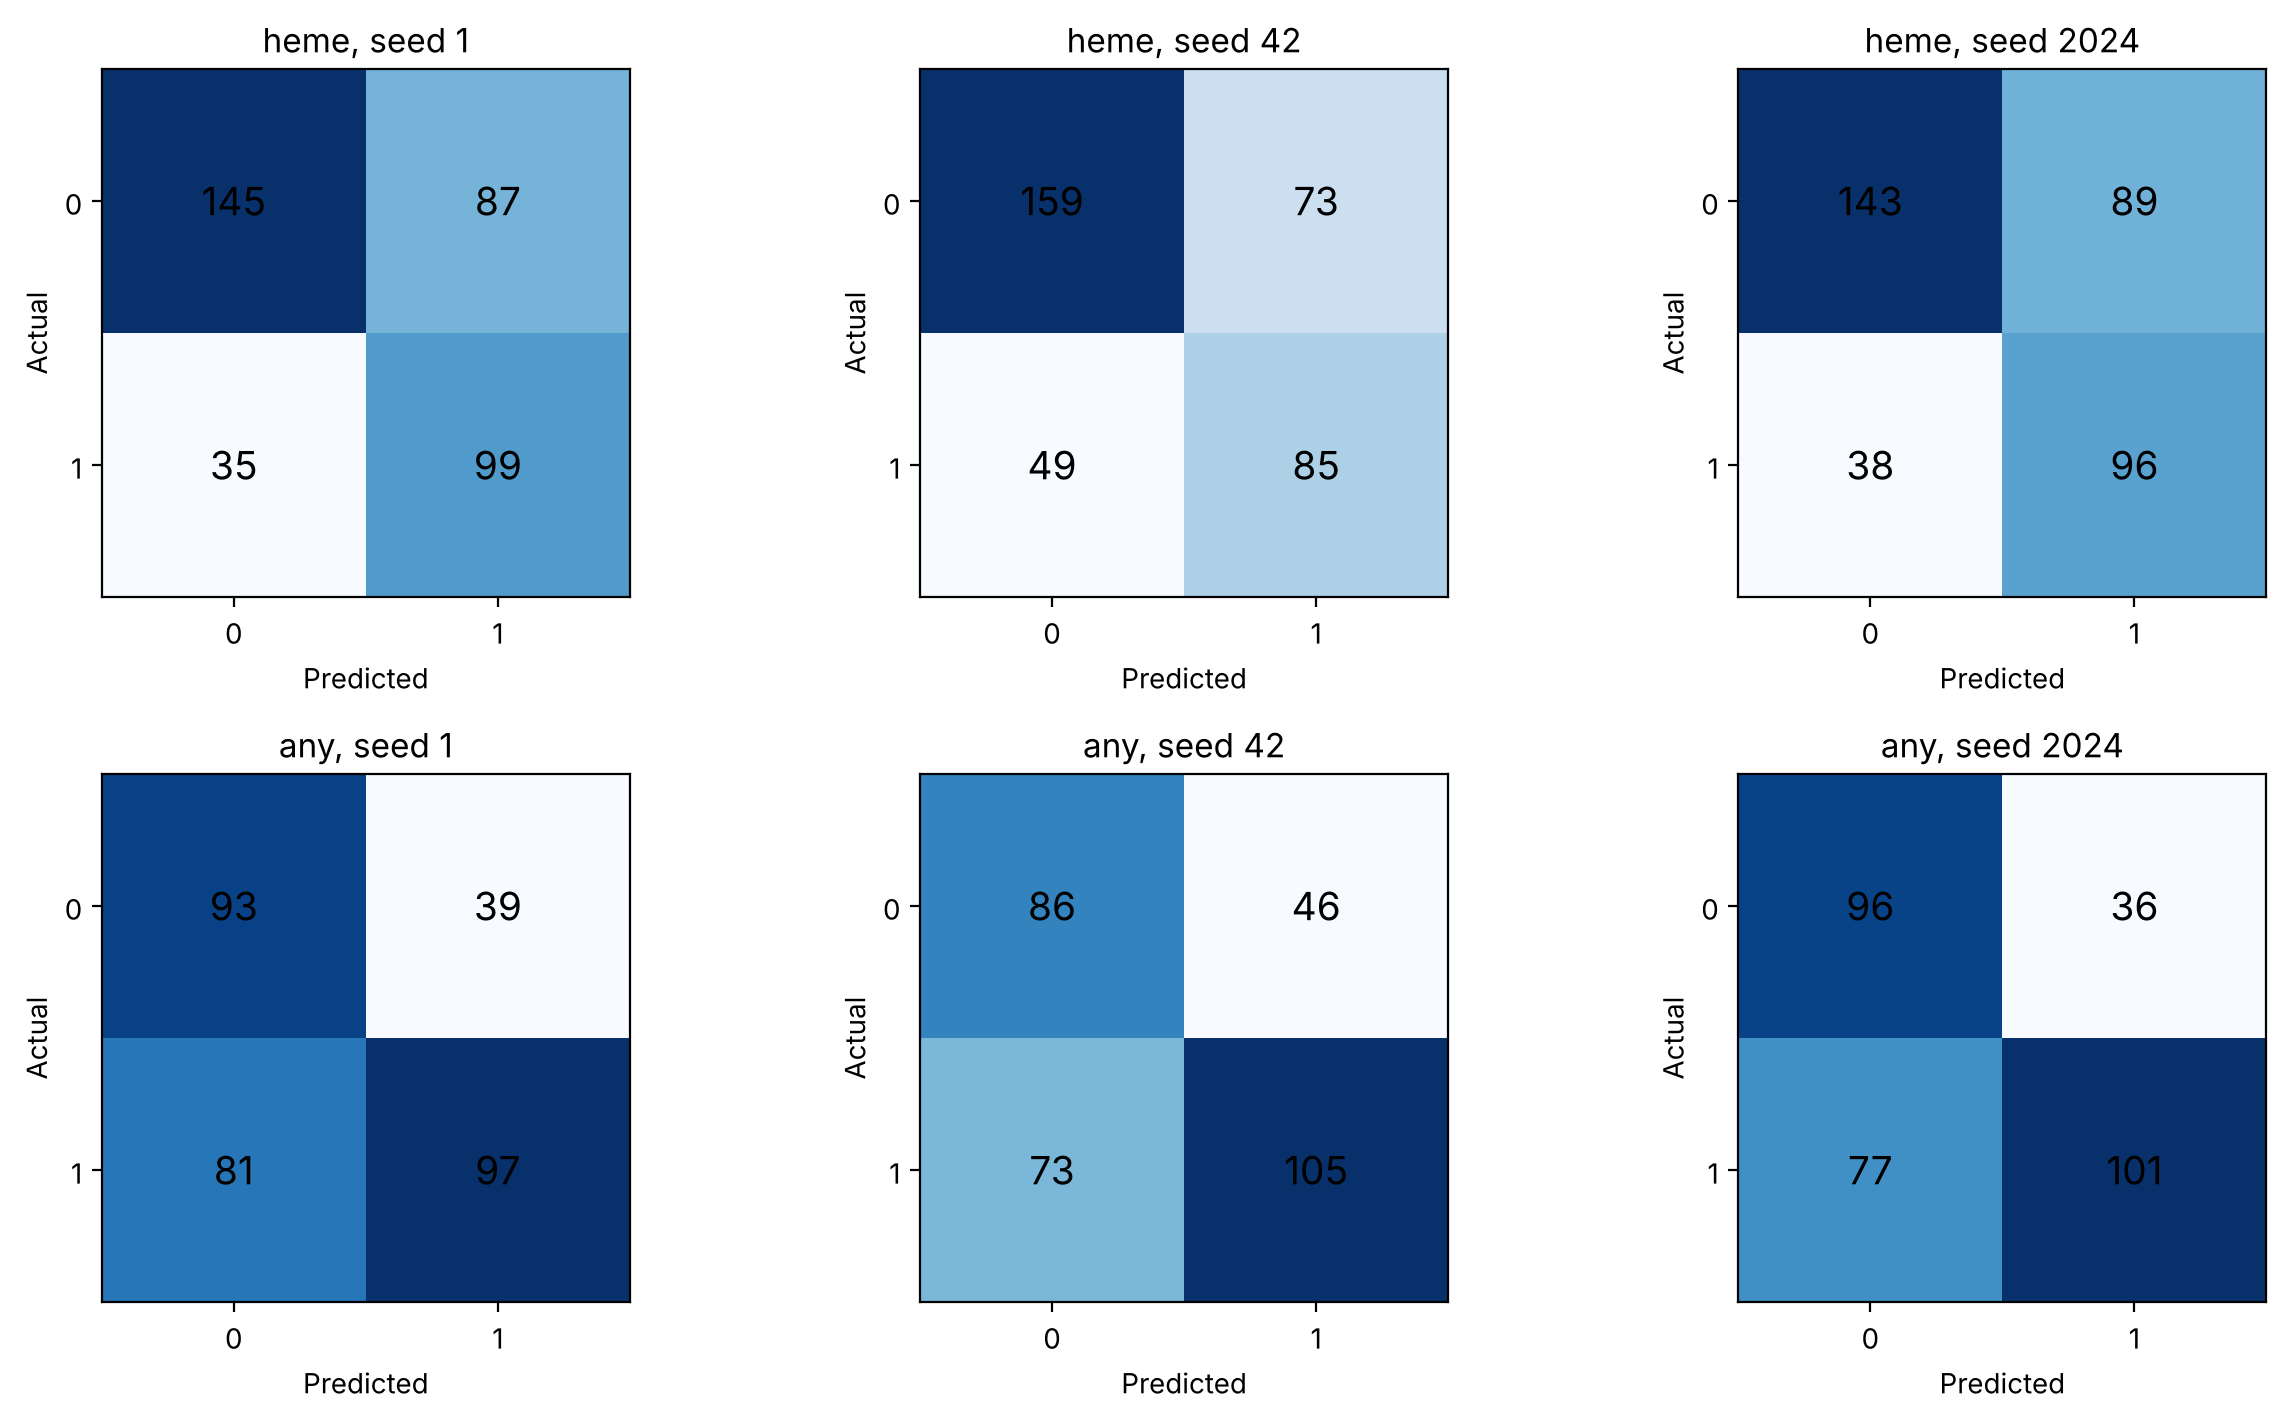

== heme
Confusion matrix (seed 42):
 [[159  73]
 [ 49  85]]


Bootstrap 95% CI (seed 42): {'AUC': array([0.684, 0.787]), 'Sensitivity': array([0.556, 0.712]), 'Specificity': array([0.626, 0.74 ])}
== any
Confusion matrix (seed 42):
 [[ 86  46]
 [ 73 105]]


Bootstrap 95% CI (seed 42): {'AUC': array([0.611, 0.73 ]), 'Sensitivity': array([0.52 , 0.667]), 'Specificity': array([0.575, 0.73 ])}


In [19]:
def boot_ci(y_, p_, pr_, B=1000):
    rng = np.random.default_rng(0)
    out = {"AUC": [], "Sensitivity": [], "Specificity": []}
    for _ in range(B):
        i = rng.integers(0, len(y_), len(y_))
        if y_[i].min() == y_[i].max(): continue
        m = metrics(y_[i], p_[i], pr_[i])
        for k in out: out[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]).round(3) for k, v in out.items()}

fig, ax = plt.subplots(len(TARGETS), len(SEEDS), figsize=(4.2 * len(SEEDS), 3.6 * len(TARGETS)))
for row, T in zip(ax, TARGETS):
    y = D[T]["y"]
    for a, s, det in zip(row, SEEDS, D[T]["final_detail"]):
        cm = confusion_matrix(y, det["pred"])
        a.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", fontsize=14)
        a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"{T}, seed {s}")
plt.tight_layout(); plt.show()
for T in TARGETS:
    y, det = D[T]["y"], D[T]["final_detail"][1]
    print(f"== {T}\nConfusion matrix (seed 42):\n", confusion_matrix(y, det["pred"]))
    print("Bootstrap 95% CI (seed 42):", boot_ci(y, det["prob"], det["pred"]))

### 13.2 Family selected in each outer fold

In [20]:
def picks_for(T):
    X, y = D[T]["X"], D[T]["y"]; picks = []
    for s in SEEDS:
        for tr, te in StratifiedKFold(N_OUTER, shuffle=True, random_state=s).split(X, y):
            gs = GridSearchCV(clone(final_pipe), cand_grid, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=s), scoring="roc_auc", n_jobs=2).fit(X.iloc[tr], y[tr])
            mdl = gs.best_params_["model"]
            picks.append(type(mdl).__name__ + ("-L1" if getattr(mdl, "penalty", "") == "l1" else ""))
    return pd.Series(picks).value_counts()
res_picks = per_target(picks_for)
pd.DataFrame(res_picks).fillna(0).astype(int)

--- heme


--- any


,heme,any
LogisticRegression,2,0
LogisticRegression-L1,6,1
RandomForestClassifier,7,13
SVC,0,1


## 14. Threshold rules

Applied to the best single configuration from Sections 7–8 for each outcome; every rule is chosen on inner folds. The fixed-threshold table uses the seed-42 nested-selection probabilities and is descriptive only.

In [21]:
cfg_all = {**simple_cfg, **ens_cfg}
for T in TARGETS:
    rs, re_ = res_simple[T], res_ens[T]
    D[T]["best_overall"] = rs.AUC.idxmax() if rs.AUC.max() >= re_.AUC.max() else re_.AUC.idxmax()
    print(T, "- configuration used below:", D[T]["best_overall"])
def thr_for(T):
    rows = {rule_: nested_cv(*cfg_all[D[T]["best_overall"]], D[T]["X"], D[T]["y"], rule=rule_) for rule_ in ["youden", "f2", "f1", "sens80", "acc"]}
    return pd.DataFrame(rows).T[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2"]].astype(float).round(3)
res_thr = per_target(thr_for)
display(stack(res_thr))
def fixed_for(T):
    y, p_ = D[T]["y"], D[T]["final_detail"][1]["prob"]; fixed = []
    for t_ in np.arange(0.2, 0.81, 0.05):
        m = metrics(y, p_, (p_ >= t_).astype(int)); m["threshold"] = round(t_, 2); fixed.append(m)
    return pd.DataFrame(fixed).set_index("threshold")[["Sensitivity", "Specificity", "Precision", "NPV", "F1", "F2", "Accuracy", "TP", "FP", "FN", "TN"]].round(3)
stack({T: fixed_for(T) for T in TARGETS})

heme - configuration used below: Random Forest
any - configuration used below: Random Forest
--- heme


--- any


AUC  Accuracy  Sensitivity  Specificity  Precision    NPV     F1     F2
target                                                                                  
heme   youden  0.738     0.646        0.664        0.635      0.512  0.767  0.578  0.627
       f2      0.738     0.465        0.940        0.191      0.402  0.847  0.563  0.741
       f1      0.738     0.637        0.751        0.570      0.503  0.800  0.602  0.683
       sens80  0.738     0.638        0.813        0.537      0.504  0.833  0.622  0.724
       acc     0.738     0.712        0.430        0.875      0.667  0.727  0.522  0.463
any    youden  0.690     0.638        0.592        0.699      0.727  0.560  0.652  0.614
       f2      0.690     0.587        0.974        0.066      0.584  0.644  0.730  0.859
       f1      0.690     0.618        0.848        0.308      0.625  0.608  0.718  0.790
       sens80  0.690     0.642        0.775        0.462      0.660  0.605  0.713  0.749
       acc     0.690     0.641        0.708        0.551      0.680  0.584  0.693  0.702

Sensitivity  Specificity  Precision    NPV     F1     F2  Accuracy   TP   FP   FN   TN
target                                                                                             
heme   0.20        1.000        0.000      0.366  0.000  0.536  0.743     0.366  134  232    0    0
       0.25        1.000        0.000      0.366  0.000  0.536  0.743     0.366  134  232    0    0
       0.30        0.985        0.082      0.383  0.905  0.551  0.749     0.413  132  213    2   19
       0.35        0.888        0.284      0.418  0.815  0.568  0.725     0.505  119  166   15   66
       0.40        0.806        0.483      0.474  0.812  0.597  0.707     0.601  108  120   26  112
       0.45        0.731        0.616      0.524  0.799  0.611  0.678     0.658   98   89   36  143
       0.50        0.634        0.698      0.548  0.768  0.588  0.615     0.675   85   70   49  162
       0.55        0.552        0.797      0.612  0.755  0.580  0.563     0.708   74   47   60  185
       0.60        0.433        0.892      0.699  0.731  0.535  0.468     0.724   58   25   76  207
       0.65        0.328        0.940      0.759  0.708  0.458  0.370     0.716   44   14   90  218
       0.70        0.201        0.966      0.771  0.677  0.320  0.236     0.686   27    8  107  224
       0.75        0.097        0.978      0.722  0.652  0.171  0.117     0.656   13    5  121  227
       0.80        0.045        0.987      0.667  0.641  0.084  0.055     0.642    6    3  128  229
any    0.20        1.000        0.000      0.574  0.000  0.730  0.871     0.574  178  132    0    0
       0.25        1.000        0.000      0.574  0.000  0.730  0.871     0.574  178  132    0    0
       0.30        1.000        0.015      0.578  1.000  0.733  0.873     0.581  178  130    0    2
       0.35        0.978        0.053      0.582  0.636  0.730  0.861     0.584  174  125    4    7
       0.40        0.910        0.182      0.600  0.600  0.723  0.825     0.600  162  108   16   24
       0.45        0.730        0.470      0.650  0.564  0.688  0.713     0.619  130   70   48   62
       0.50        0.579        0.697      0.720  0.551  0.642  0.602     0.629  103   40   75   92
       0.55        0.427        0.833      0.776  0.519  0.551  0.469     0.600   76   22  102  110
       0.60        0.264        0.909      0.797  0.478  0.397  0.305     0.539   47   12  131  120
       0.65        0.124        0.947      0.759  0.445  0.213  0.148     0.474   22    7  156  125
       0.70        0.039        0.985      0.778  0.432  0.075  0.049     0.442    7    2  171  130
       0.75        0.028        1.000      1.000  0.433  0.055  0.035     0.442    5    0  173  132
       0.80        0.000        1.000      0.000  0.426  0.000  0.000     0.426    0    0  178  132

## 15. Calibration

Platt scaling wraps the whole pipeline and is tuned inside the inner loop.

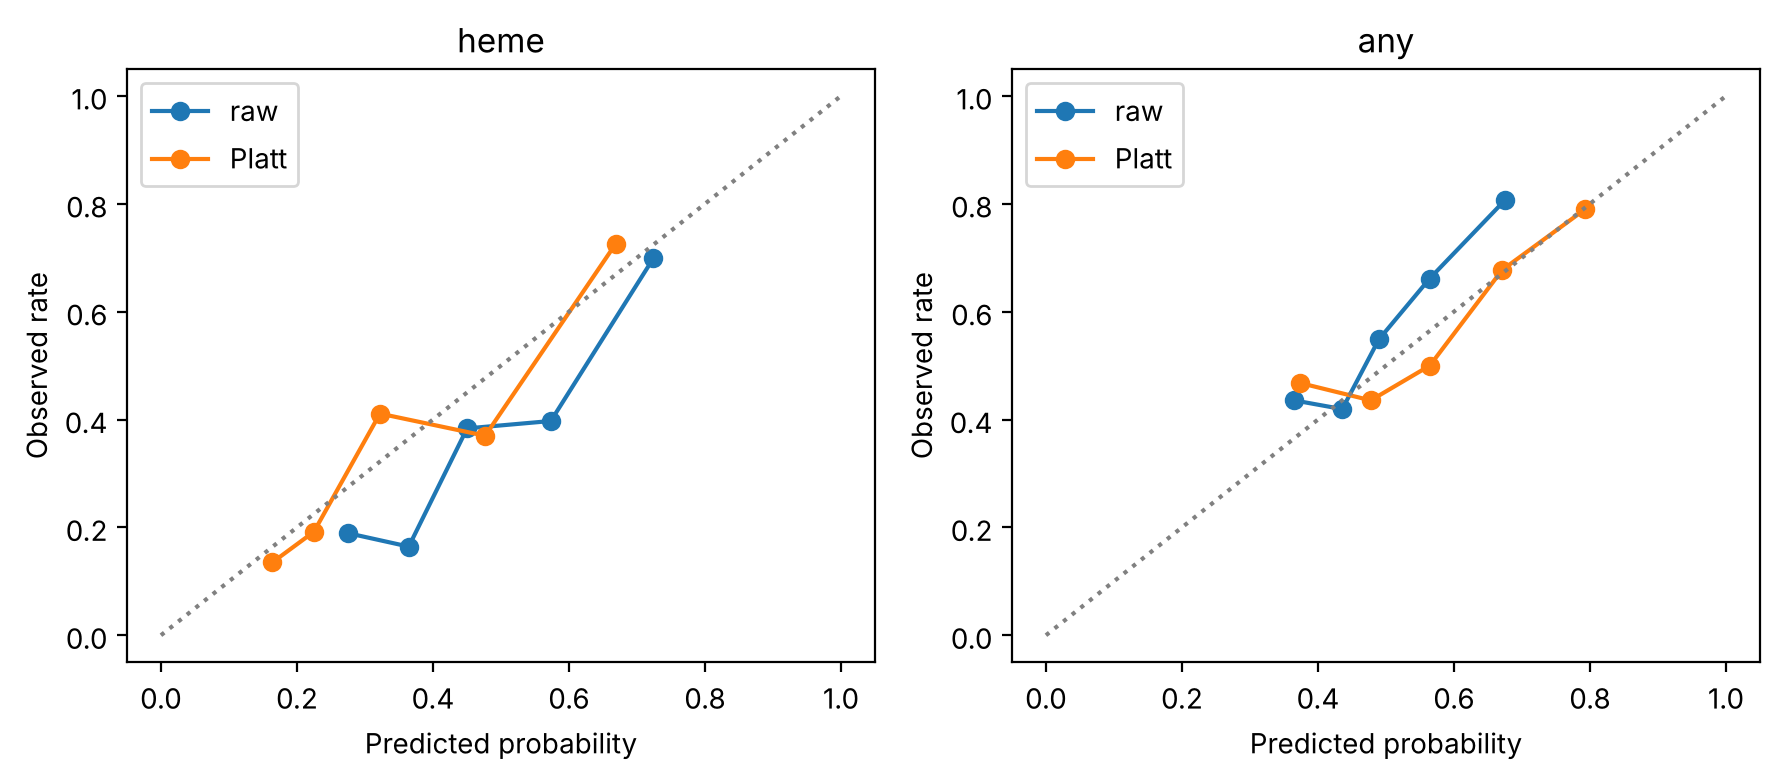

Raw  Platt
target                                
heme   AUC                0.738  0.742
       Brier              0.209  0.193
       Calibration slope  1.219  1.027
any    AUC                0.690  0.684
       Brier              0.227  0.221
       Calibration slope  1.387  0.885

In [22]:
def cal_slope(y_, p_):
    lp = np.log(np.clip(p_, 1e-6, 1 - 1e-6) / (1 - np.clip(p_, 1e-6, 1 - 1e-6)))
    return LogisticRegression(C=1e6).fit(lp.reshape(-1, 1), y_).coef_[0][0]
fig, axs = plt.subplots(1, len(TARGETS), figsize=(4.5 * len(TARGETS), 4))
res_cal = {}
for a, T in zip(axs, TARGETS):
    X, y = D[T]["X"], D[T]["y"]
    base_pipe, base_grid = cfg_all[D[T]["best_overall"]]
    raw_s, raw_d = nested_cv(base_pipe, base_grid, X, y, return_detail=True)
    plat_pipe = CalibratedClassifierCV(clone(base_pipe), cv=4, method="sigmoid")
    plat_grid = {"estimator__" + k: v for k, v in base_grid.items()} if base_grid else None
    pl_s, pl_d = nested_cv(plat_pipe, plat_grid, X, y, return_detail=True)
    res_cal[T] = pd.DataFrame({"Raw": [raw_s.AUC, raw_s.Brier, cal_slope(y, raw_d[1]["prob"])],
                               "Platt": [pl_s.AUC, pl_s.Brier, cal_slope(y, pl_d[1]["prob"])]},
                              index=["AUC", "Brier", "Calibration slope"]).round(3)
    for lab, p_ in [("raw", raw_d[1]["prob"]), ("Platt", pl_d[1]["prob"])]:
        bins = pd.qcut(p_, 5, duplicates="drop")
        g = pd.DataFrame({"p": p_, "y": y}).groupby(bins, observed=True).mean()
        a.plot(g.p, g.y, "o-", label=lab)
    a.plot([0, 1], [0, 1], ":", c="gray"); a.set_title(T); a.set_xlabel("Predicted probability"); a.set_ylabel("Observed rate"); a.legend()
plt.tight_layout(); plt.show()
stack(res_cal)

## 16. Risk tiers

Tertile cut-points come from inner out-of-fold probabilities of each training fold.

In [23]:
def tiers_for(T):
    y = D[T]["y"]; tiers = []
    for s, det in zip(SEEDS, D[T]["final_detail"]):
        t_ = pd.DataFrame({"tier": pd.Series(det["tert"]).map({0: "1-low", 1: "2-intermediate", 2: "3-high"}), "y": y})
        g = t_.groupby("tier").y.agg(["size", "sum", "mean"]); g["seed"] = s; tiers.append(g)
    tiers = pd.concat(tiers).reset_index().groupby("tier")[["size", "sum", "mean"]].mean().round(3)
    tiers.columns = ["mean n", "mean events", "event rate"]
    return tiers
res_tiers = {T: tiers_for(T) for T in TARGETS}
stack(res_tiers)

mean n  mean events  event rate
target                                                 
heme   1-low           130.333       21.667       0.166
       2-intermediate  112.000       38.667       0.345
       3-high          123.667       73.667       0.596
any    1-low           115.000       45.667       0.397
       2-intermediate   84.667       47.333       0.559
       3-high          110.333       85.000       0.771

## 17. Subgroups (seed 42, nested selection; groups with < 15 patients or one class are skipped)

In [24]:
def sub_for(T):
    d, y, det = D[T]["d"], D[T]["y"], D[T]["final_detail"][1]
    sub_rows = []
    groups = {"Arm (indrx)": d.indrx, "Carboplatin": d.carbo.map({0: "no", 1: "yes"}), "Age group (AGE_C)": d.AGE_C,
              "White (WHITE)": d.WHITE, "ER": d.er, "Stage (stra1_stage)": d.stra1_stage}
    for gname, col in groups.items():
        for lvl in sorted(col.dropna().unique()):
            k = (col == lvl).values
            if k.sum() < 15 or y[k].min() == y[k].max(): continue
            m = metrics(y[k], det["prob"][k], det["pred"][k])
            sub_rows.append(dict(group=gname, level=lvl, n=int(k.sum()), events=int(y[k].sum()), AUC=m["AUC"], Sensitivity=m["Sensitivity"], Specificity=m["Specificity"], F2=m["F2"]))
    return pd.DataFrame(sub_rows).round(3)
res_sub = {T: sub_for(T) for T in TARGETS}
stack(res_sub)

group level    n  events    AUC  Sensitivity  Specificity     F2
target                                                                                   
heme   0           Arm (indrx)     1  102      20  0.669        0.200        0.890  0.215
       1           Arm (indrx)     2  104      24  0.507        0.125        0.888  0.139
       2           Arm (indrx)     3   77      37  0.700        0.811        0.300  0.728
       3           Arm (indrx)     4   83      53  0.607        0.906        0.100  0.836
       4           Carboplatin    no  206      44  0.590        0.159        0.889  0.174
       5           Carboplatin   yes  160      90  0.675        0.867        0.214  0.791
       6     Age group (AGE_C)     1   85      26  0.756        0.615        0.695  0.580
       7     Age group (AGE_C)     2  221      83  0.765        0.663        0.703  0.643
       8     Age group (AGE_C)     3   60      25  0.582        0.560        0.600  0.547
       9         White (WHITE)     1  265      94  0.730        0.628        0.655  0.597
       10        White (WHITE)     2  101      40  0.756        0.650        0.770  0.650
       11                   ER   1.0  337     129  0.727        0.620        0.678  0.603
       12                   ER   2.0   24       5  0.926        1.000        0.789  0.862
       13  Stage (stra1_stage)     1  247      89  0.710        0.652        0.684  0.625
       14  Stage (stra1_stage)     2  119      45  0.783        0.600        0.689  0.587
any    0           Arm (indrx)     1   93      41  0.533        0.098        0.885  0.115
       1           Arm (indrx)     2   78      35  0.514        0.200        0.651  0.216
       2           Arm (indrx)     3   69      44  0.705        0.818        0.480  0.800
       3           Arm (indrx)     4   70      58  0.352        1.000        0.000  0.960
       4           Carboplatin    no  171      76  0.525        0.145        0.779  0.164
       5           Carboplatin   yes  139     102  0.631        0.922        0.324  0.892
       6     Age group (AGE_C)     1   75      37  0.730        0.649        0.632  0.645
       7     Age group (AGE_C)     2  185     108  0.704        0.620        0.688  0.641
       8     Age group (AGE_C)     3   50      33  0.431        0.424        0.529  0.455
       9         White (WHITE)     1  225     117  0.655        0.556        0.694  0.574
       10        White (WHITE)     2   85      61  0.654        0.656        0.458  0.673
       11                   ER   1.0  285     166  0.666        0.602        0.630  0.619
       12                   ER   2.0   20      11  0.747        0.455        0.889  0.500
       13  Stage (stra1_stage)     1  213     124  0.657        0.573        0.629  0.592
       14  Stage (stra1_stage)     2   97      54  0.694        0.630        0.698  0.646

## 18. Permutation importance (held-out folds, seed 42) and Mann–Whitney test (descriptive)

In [25]:
def imp_for(T):
    X, y = D[T]["X"], D[T]["y"]; imp = []
    bp, bg = cfg_all[D[T]["best_overall"]]
    for tr, te in StratifiedKFold(N_OUTER, shuffle=True, random_state=42).split(X, y):
        m_ = (GridSearchCV(clone(bp), bg, cv=StratifiedKFold(N_INNER, shuffle=True, random_state=42), scoring="roc_auc").fit(X.iloc[tr], y[tr]).best_estimator_
              if bg else clone(bp).fit(X.iloc[tr], y[tr]))
        r = permutation_importance(m_, X.iloc[te], y[te], scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=2)
        imp.append(r.importances_mean)
    imp = pd.DataFrame({"importance (AUC drop)": np.mean(imp, 0)}, index=FEATURES).sort_values("importance (AUC drop)", ascending=False)
    top = imp.head(10).copy()
    top["Mann-Whitney p"] = [mannwhitneyu(X[c][y == 1].dropna(), X[c][y == 0].dropna()).pvalue for c in top.index]
    return top.round(4)
res_imp = per_target(imp_for)
stack(res_imp)

--- heme


--- any


importance (AUC drop)  Mann-Whitney p
target                                                                
heme   factora                                  0.0446          0.0000
       indrx                                    0.0166          0.0000
       e_max_pain                               0.0122          0.4588
       e_count_g2                               0.0085          0.0000
       e_first_day                              0.0063          0.4340
       e_max_thrombocytopenia_h                 0.0057          0.0000
       e_max_thrombocytopenia                   0.0039          0.0000
       e_max_neutropenia_h                      0.0036          0.0000
       e_max_gi                                 0.0015          0.0005
       e_max_neutropenia                        0.0012          0.0000
any    indrx                                    0.0314          0.0000
       factora                                  0.0278          0.0000
       WHITE                                    0.0143          0.0017
       e_count_g2                               0.0106          0.0025
       e_max_grade                              0.0080          0.0137
       tsizemri                                 0.0044          0.0688
       e_first_day                              0.0032          0.6161
       e_max_gi                                 0.0026          0.0120
       e_max_metabolic_lab                      0.0023          0.2224
       e_max_neuropathy                         0.0020          0.3077

## 19. Robustness on five unseen seeds

In [26]:
def rob_for(T):
    rob = []
    for s in ROB_SEEDS:
        r = nested_cv(*cfg_all[D[T]["best_overall"]], D[T]["X"], D[T]["y"], seeds=[s]); r["seed"] = s; rob.append(r)
    rob = pd.DataFrame(rob).set_index("seed")[["AUC", "Sensitivity", "Specificity", "F1", "F2", "Accuracy"]].astype(float)
    rob.loc["mean"] = rob.mean(); rob.loc["sd"] = rob.iloc[:-1].std()
    return rob
res_rob = per_target(rob_for)
stack(res_rob).round(3)

--- heme


--- any


AUC  Sensitivity  Specificity     F1     F2  Accuracy
target                                                                
heme   7.0     0.718        0.604        0.681  0.561  0.586     0.653
       99.0    0.743        0.619        0.703  0.580  0.603     0.672
       314.0   0.737        0.672        0.651  0.590  0.636     0.658
       777.0   0.728        0.649        0.711  0.604  0.630     0.689
       2025.0  0.731        0.716        0.655  0.619  0.674     0.678
       mean    0.731        0.652        0.680  0.591  0.626     0.670
       sd      0.009        0.044        0.027  0.022  0.034     0.014
any    7.0     0.658        0.579        0.644  0.628  0.597     0.606
       99.0    0.686        0.528        0.727  0.610  0.558     0.613
       314.0   0.672        0.601        0.644  0.645  0.618     0.619
       777.0   0.688        0.551        0.735  0.630  0.580     0.629
       2025.0  0.686        0.539        0.742  0.623  0.570     0.626
       mean    0.678        0.560        0.698  0.627  0.585     0.619
       sd      0.013        0.030        0.050  0.012  0.023     0.009

## 20. RQ6 — specific outcomes versus any grade ≥3 AE, with and without early AEs

Each outcome has its own landmark cohort (Section 3). For every outcome the same nested model selection (Section 13) is run twice: with the 19 baseline variables only, and with baseline variables plus the 18 early-AE features. Outcomes with fewer than 40 events after day 28 are not modelled. ΔAUC is the paired difference on the seed-42 out-of-fold predictions (identical folds for both feature sets), with a 1,000-resample paired bootstrap interval. For `heme` and `any`, the baseline + early-AE results are those of Section 13.

In [27]:
FEATURE_SETS = {"Baseline": BASE, "Baseline + early AEs": FEATURES}
def paired_delta(y_, p0, p1, B=1000):
    rng = np.random.default_rng(0); dlt = []
    for _ in range(B):
        i = rng.integers(0, len(y_), len(y_))
        if y_[i].min() == y_[i].max(): continue
        dlt.append(roc_auc_score(y_[i], p1[i]) - roc_auc_score(y_[i], p0[i]))
    return np.percentile(dlt, [2.5, 97.5])

rq6_rows, RQ6 = [], {}
for name in OUTCOMES:
    d = cohort(name); y = d.y.values
    if y.sum() < 40:
        print(f"{name}: {y.sum()} events, not modelled"); continue
    for fs, feats in FEATURE_SETS.items():
        t0 = time.time()
        if name in TARGETS and fs == "Baseline + early AEs":
            s, det = D[name]["final_sum"], D[name]["final_detail"]
        else:
            s, det = nested_cv(make_pipe(LogisticRegression(), prep=make_prep(features=feats)), cand_grid, d[feats], y, return_detail=True)
        RQ6[(name, fs)] = det[1]["prob"]
        rq6_rows.append(dict(outcome=name, type="any" if name == "any" else "specific", features=fs, n=len(d), events=int(y.sum()),
                             prevalence=y.mean(), AUC=s.AUC, AUC_sd=s.AUC_sd, Sensitivity=s.Sensitivity, Specificity=s.Specificity,
                             Accuracy=s.Accuracy, F1=s.F1, F2=s.F2, Brier=s.Brier))
        print(f"{name:20s} {fs:22s} n={len(d)} events={y.sum()} AUC={s.AUC:.3f} ({time.time()-t0:.0f}s)")
    lo, hi = paired_delta(y, RQ6[(name, "Baseline")], RQ6[(name, "Baseline + early AEs")])
    rq6_rows[-1].update(dAUC=rq6_rows[-1]["AUC"] - rq6_rows[-2]["AUC"], dAUC_lo=lo, dAUC_hi=hi)
res_rq6 = pd.DataFrame(rq6_rows).set_index(["outcome", "features"])
res_rq6.round(3)

heme                 Baseline               n=366 events=134 AUC=0.674 (82s)
heme                 Baseline + early AEs   n=366 events=134 AUC=0.737 (0s)


any                  Baseline               n=310 events=178 AUC=0.666 (85s)
any                  Baseline + early AEs   n=310 events=178 AUC=0.683 (0s)


Neutropenia          Baseline               n=372 events=120 AUC=0.600 (66s)


Neutropenia          Baseline + early AEs   n=372 events=120 AUC=0.697 (91s)


Leukopenia           Baseline               n=430 events=56 AUC=0.488 (71s)


Leukopenia           Baseline + early AEs   n=430 events=56 AUC=0.618 (80s)


... (7 outputs left out)

Fatigue              Baseline + early AEs   n=437 events=51 AUC=0.547 (87s)


Gastrointestinal     Baseline               n=437 events=43 AUC=0.504 (74s)


Gastrointestinal     Baseline + early AEs   n=437 events=43 AUC=0.511 (86s)


type    n  events  prevalence    AUC  AUC_sd  Sensitivity  Specificity  Accuracy     F1     F2  Brier   dAUC  dAUC_lo  dAUC_hi
outcome             features                                                                                                                                                
heme                Baseline              specific  366     134       0.366  0.674   0.007        0.672        0.687     0.681  0.607  0.644  0.223    NaN      NaN      NaN
                    Baseline + early AEs  specific  366     134       0.366  0.737   0.002        0.697        0.642     0.662  0.601  0.655  0.211  0.063    0.024    0.101
any                 Baseline                   any  310     178       0.574  0.666   0.024        0.601        0.672     0.631  0.652  0.620  0.234    NaN      NaN      NaN
                    Baseline + early AEs       any  310     178       0.574  0.683   0.018        0.567        0.694     0.622  0.632  0.592  0.228  0.017   -0.026    0.058
Neutropenia         Baseline              specific  372     120       0.323  0.600   0.014        0.583        0.694     0.659  0.524  0.558  0.221    NaN      NaN      NaN
                    Baseline + early AEs  specific  372     120       0.323  0.697   0.022        0.633        0.667     0.656  0.543  0.594  0.216  0.097    0.052    0.163
Leukopenia          Baseline              specific  430      56       0.130  0.488   0.022        0.464        0.523     0.516  0.200  0.304  0.176    NaN      NaN      NaN
                    Baseline + early AEs  specific  430      56       0.130  0.618   0.016        0.560        0.770     0.743  0.364  0.459  0.196  0.131    0.006    0.211
Thrombocytopenia    Baseline              specific  436      52       0.119  0.689   0.052        0.808        0.557     0.587  0.318  0.500  0.197    NaN      NaN      NaN
                    Baseline + early AEs  specific  436      52       0.119  0.734   0.054        0.712        0.668     0.673  0.342  0.496  0.184  0.045    0.023    0.183
Febrile neutropenia Baseline              specific  441      56       0.127  0.543   0.014        0.595        0.572     0.575  0.263  0.395  0.180    NaN      NaN      NaN
                    Baseline + early AEs  specific  441      56       0.127  0.532   0.018        0.506        0.566     0.559  0.225  0.338  0.197 -0.011   -0.036    0.025
Infection           Baseline              specific  435      77       0.177  0.574   0.024        0.567        0.601     0.595  0.331  0.441  0.214    NaN      NaN      NaN
                    Baseline + early AEs  specific  435      77       0.177  0.552   0.008        0.545        0.602     0.592  0.322  0.427  0.212 -0.023   -0.122    0.072
Fatigue             Baseline              specific  437      51       0.117  0.551   0.026        0.431        0.590     0.571  0.188  0.284  0.174    NaN      NaN      NaN
                    Baseline + early AEs  specific  437      51       0.117  0.547   0.011        0.497        0.577     0.568  0.212  0.322  0.145 -0.004   -0.142    0.099
Gastrointestinal    Baseline              specific  437      43       0.098  0.504   0.028        0.411        0.620     0.600  0.167  0.259  0.182    NaN      NaN      NaN
                    Baseline + early AEs  specific  437      43       0.098  0.511   0.022        0.512        0.528     0.526  0.176  0.288  0.165  0.007   -0.152    0.129

Compact view: AUC by outcome and feature set, with the gain from early AEs.

In [28]:
w = res_rq6.AUC.unstack("features")[list(FEATURE_SETS)]
w = w.join(res_rq6.xs("Baseline + early AEs", level="features")[["type", "n", "events", "dAUC", "dAUC_lo", "dAUC_hi"]])
w = w.loc[[o for o in OUTCOMES if o in w.index]]
w.round(3)

,Baseline,Baseline + early AEs,type,n,events,dAUC,dAUC_lo,dAUC_hi
outcome,,,,,,,,
heme,0.674,0.737,specific,366,134,0.063,0.024,0.101
any,0.666,0.683,any,310,178,0.017,-0.026,0.058
Neutropenia,0.600,0.697,specific,372,120,0.097,0.052,0.163
Leukopenia,0.488,0.618,specific,430,56,0.131,0.006,0.211
Thrombocytopenia,0.689,0.734,specific,436,52,0.045,0.023,0.183
Febrile neutropenia,0.543,0.532,specific,441,56,-0.011,-0.036,0.025
Infection,0.574,0.552,specific,435,77,-0.023,-0.122,0.072
Fatigue,0.551,0.547,specific,437,51,-0.004,-0.142,0.099
Gastrointestinal,0.504,0.511,specific,437,43,0.007,-0.152,0.129


## 21. Summary and saved outputs

Per-family best values are optimistic (chosen after the fact); the primary estimate is the nested-selection row.

In [29]:
import os
os.makedirs("results", exist_ok=True)
for T in TARGETS:
    summary = pd.DataFrame({
        "Arm only": D[T]["arm_only"],
        D[T]["rule_name"]: D[T]["rule_m"],
        "Best preprocessing: " + res_prep[T].AUC.idxmax(): res_prep[T].loc[res_prep[T].AUC.idxmax()],
        "Best simple: " + res_simple[T].AUC.idxmax(): res_simple[T].loc[res_simple[T].AUC.idxmax()],
        "Best ensemble: " + res_ens[T].AUC.idxmax(): res_ens[T].loc[res_ens[T].AUC.idxmax()],
        "Best reduction: " + res_dr[T].AUC.idxmax(): res_dr[T].loc[res_dr[T].AUC.idxmax()],
        "Best imbalance: " + res_imb[T].AUC.idxmax(): res_imb[T].loc[res_imb[T].AUC.idxmax()],
        "Final (nested selection)": D[T]["final_sum"],
    }).T[["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "F2"]].astype(float).round(3)
    summary.to_csv(f"results/summary_{T}.csv"); display(summary)
    for name, df_ in {"prep": res_prep, "simple": res_simple, "ens": res_ens, "reg": res_reg, "dr": res_dr, "imb": res_imb,
                      "thr": res_thr, "tiers": res_tiers, "cal": res_cal, "val": res_val, "imp": res_imp, "rob": res_rob, "picks": res_picks}.items():
        df_[T].to_csv(f"results/res_{T}_{name}.csv")
    res_sub[T].to_csv(f"results/res_{T}_sub.csv", index=False)
res_rq6.to_csv("results/rq6_specific_vs_any.csv")
print(f"Total run time: {(time.time()-T0)/60:.1f} min")

,AUC,Accuracy,Sensitivity,Specificity,Precision,F1,F2
Arm only,0.683,0.689,0.672,0.698,0.562,0.612,0.647
Rule: ANC or platelet grade >=1 by day 28,0.656,0.694,0.515,0.797,0.595,0.552,0.529
Best preprocessing: median + ordinal categories,0.737,0.661,0.659,0.662,0.532,0.586,0.627
Best simple: LR L1 (Lasso),0.733,0.671,0.669,0.672,0.543,0.596,0.637
Best ensemble: Random Forest,0.738,0.646,0.664,0.635,0.512,0.578,0.627
Best reduction: SelectKBest ANOVA F,0.744,0.671,0.639,0.690,0.545,0.587,0.617
Best imbalance: class_weight balanced,0.734,0.662,0.590,0.704,0.536,0.560,0.577
Final (nested selection),0.737,0.662,0.697,0.642,0.530,0.601,0.655


,AUC,Accuracy,Sensitivity,Specificity,Precision,F1,F2
Arm only,0.624,0.635,0.573,0.720,0.734,0.644,0.599
Rule: any AE grade >=2 by day 28,0.569,0.590,0.713,0.424,0.626,0.667,0.694
Best preprocessing: median + minmax scaler,0.690,0.649,0.581,0.742,0.753,0.655,0.608
Best simple: LR ElasticNet,0.679,0.616,0.582,0.662,0.700,0.635,0.602
Best ensemble: Random Forest,0.690,0.638,0.592,0.699,0.727,0.652,0.614
Best reduction: No reduction (all features),0.676,0.632,0.614,0.657,0.708,0.657,0.631
Best imbalance: SMOTE + Random Forest,0.695,0.634,0.614,0.662,0.710,0.659,0.631
Final (nested selection),0.683,0.622,0.567,0.694,0.715,0.632,0.592


Total run time: 114.2 min
